# BÀI 5 — PHÂN LOẠI ẢNH CIFAR-10 VỚI CNN

**Đề bài:** Xây dựng mô hình phân loại ảnh trên bộ dữ liệu CIFAR-10 tại
[Kaggle](https://www.kaggle.com/c/cifar-10).

**Kết quả chạy đã lưu:** Đủ 8 cấu hình × 16 epoch. ResNet-tiny được chọn bằng validation loss,
checkpoint epoch 14; validation accuracy 83,60%, validation loss 0,4894.
Đánh giá cuối trên 5.000 ảnh test nội bộ: **4.117 đúng, 883 sai, accuracy 82,34%, loss 0,5104**.

Bản này chứa riêng lời giải CIFAR-10

## Đối chiếu nội dung bài giảng

| Nội dung bài giảng | Phần lời giải | Bằng chứng |
|---|---|---|
| Đề bài CIFAR-10 | BT1 | Ảnh RGB 32×32, 10 lớp |
| Chia dữ liệu, chống leakage | BT1–BT2 | 40.000/5.000/5.000; ID không trùng; mean/std chỉ train |
| Dataset/DataLoader và augmentation | BT2 | RandomAffine + ColorJitter, chỉ train |
| Công thức và kích thước tensor | BT3 | Tính kích thước qua 4 mạng; cat và residual khớp |
| Ba hàm train/evaluate/test | BT4 | Dùng nguyên hàm và cách cộng metrics theo số mẫu |
| Engine, checkpoint, log epoch | BT4–BT5 | 128 epoch; chọn checkpoint theo validation loss |
| LeNet E0–E4 | BT5 | Tanh/Avg, ReLU/Max, Dropout/WD, Aug, BatchNorm |
| VGG/Inception/ResNet-tiny | BT5 | Đúng các định nghĩa mạng trong bài, đầu vào 3 kênh |
| So sánh validation | BT6 | Loss, accuracy, gap, số lỗi, tham số, epoch chọn, thời gian |
| Ảnh sai sau từng thí nghiệm | BT5/BT7 | 8 nhóm ảnh sai, nhãn thật/dự đoán, confidence và P(nhãn thật) |
| Phân tích sâu validation | BT7 | Lỗi theo lớp, confusion matrix, hai nhóm confidence |
| Test cuối và report | BT8 | Một test_model; loss, accuracy, P/R/F1/support, confusion matrix |
| Feature maps | BT9 | Conv2d đầu tiên; 8 kênh minh họa trên validation |
| Kết luận, giới hạn, tái lập | BT10 | Một seed, 16 epoch, mạng tiny; lưu cấu hình, ID, checkpoint |

## BT1. Nguồn dữ liệu và quy trình đánh giá

Sử dụng `train.7z` và `trainLabels.csv` từ gói CIFAR-10 Kaggle.
Chia toàn bộ **50.000 ảnh có nhãn** thành **40.000 train, 5.000 validation, 5.000 test nội bộ**,
seed 42; mỗi lớp có 4.000/500/500 ảnh tương ứng.
Tập test Kaggle không có nhãn công khai nên điểm ở đây là điểm test nội bộ,
khác tập test 10.000 ảnh của bản CIFAR-10 gốc.

Các lớp theo thứ tự nhãn 0–9: airplane, automobile, bird, cat, deer, dog,
frog, horse, ship, truck. Ảnh gốc là RGB 32×32, không cần phóng to.

**Quy trình:** chia dữ liệu → tính mean/std trên train → augmentation chỉ trên train →
huấn luyện, chọn checkpoint và mô hình bằng validation → phân tích lỗi validation → test cuối.


In [1]:
import os, time, random, copy
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from IPython.display import display

SEED = 42
EPOCHS = 16
BATCH_SIZE = 64
LR = 1e-3
N_TRAIN_PER_CLASS = 4000
N_VAL_PER_CLASS = 500
N_TEST_PER_CLASS = 500

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(2, os.cpu_count() or 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE_DIR = Path.cwd()
if (BASE_DIR / "Bai_5_CNN_ban_nop").is_dir():
    BASE_DIR = BASE_DIR / "Bai_5_CNN_ban_nop"
DATA_DIR = BASE_DIR / "data"
RESULT_DIR = BASE_DIR / "ket_qua"
DATA_DIR.mkdir(exist_ok=True, parents=True)
RESULT_DIR.mkdir(exist_ok=True, parents=True)
print(f"PyTorch {torch.__version__} | Device = {DEVICE} | seed = {SEED}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(f"Epochs = {EPOCHS}; batch size = {BATCH_SIZE}; learning rate = {LR}")

PyTorch 2.11.0+cu128 | Device = cuda | seed = 42
GPU: NVIDIA GeForce RTX 3080 Laptop GPU
Epochs = 16; batch size = 64; learning rate = 0.001


### Chuẩn bị dữ liệu

Đặt `trainLabels.csv` và thư mục `train` gồm các tệp `1.png`, ..., `50000.png`
trong thư mục `data` cạnh notebook. Nếu chỉ có `cifar-10.zip` hoặc `train.7z`,
cell dưới sẽ giải nén phần train; cần `py7zr` cho định dạng 7z.
Trên máy khác, có thể cài `torch torchvision numpy pandas matplotlib scikit-learn pillow py7zr`
bằng pip trong môi trường Python dùng để mở notebook.

In [2]:
# Chỉ giải nén các tệp train cần thiết; không giải nén bộ test Kaggle không có nhãn.
zip_candidates = [
    BASE_DIR / "cifar-10.zip", DATA_DIR / "cifar-10.zip",
    BASE_DIR.parent / "cifar-10.zip", BASE_DIR.parent.parent / "cifar-10.zip",
]
if not (DATA_DIR / "trainLabels.csv").exists() or not (DATA_DIR / "train").is_dir():
    for archive in zip_candidates:
        if archive.is_file():
            with zipfile.ZipFile(archive) as z:
                for name in ["trainLabels.csv", "train.7z"]:
                    if not (DATA_DIR / name).exists():
                        z.extract(name, DATA_DIR)
            break
if not (DATA_DIR / "train" / "50000.png").is_file():
    if not (DATA_DIR / "train.7z").is_file():
        raise FileNotFoundError("Cần data/train/*.png hoặc train.7z từ CIFAR-10 Kaggle.")
    import py7zr
    with py7zr.SevenZipFile(DATA_DIR / "train.7z", mode="r") as archive:
        archive.extractall(path=DATA_DIR)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}
labels_df = pd.read_csv(DATA_DIR / "trainLabels.csv").sort_values("id").reset_index(drop=True)
assert len(labels_df) == 50000 and labels_df["id"].is_unique
assert set(labels_df["label"]) == set(CLASS_NAMES)
labels = labels_df["label"].map(label_to_id).to_numpy(dtype=np.int64)

# Đọc ảnh theo đúng ID của bảng nhãn. Không chuyển thành ảnh xám, không phóng ảnh.
cache_file = DATA_DIR / "kaggle_train_rgb_uint8.npy"
if cache_file.exists():
    imgs = np.load(cache_file)
else:
    imgs = np.empty((len(labels_df), 32, 32, 3), dtype=np.uint8)
    for row, image_id in enumerate(labels_df["id"]):
        with Image.open(DATA_DIR / "train" / f"{image_id}.png") as image:
            imgs[row] = np.asarray(image.convert("RGB"))
    np.save(cache_file, imgs)
assert imgs.shape == (50000, 32, 32, 3) and imgs.dtype == np.uint8
print("Ảnh có nhãn Kaggle:", imgs.shape, "| kiểu:", imgs.dtype)
print("Thứ tự lớp:", label_to_id)

Ảnh có nhãn Kaggle: (50000, 32, 32, 3) | kiểu: uint8
Thứ tự lớp: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


Train/Validation/Test nội bộ: 40000/5000/5000
Input CNN: (40000, 3, 32, 32); mean train = 0.473450; std train = 0.251525


,class,train,validation,test_noi_bo
0,airplane,4000,500,500
1,automobile,4000,500,500
2,bird,4000,500,500
3,cat,4000,500,500
4,deer,4000,500,500
5,dog,4000,500,500
6,frog,4000,500,500
7,horse,4000,500,500
8,ship,4000,500,500
9,truck,4000,500,500


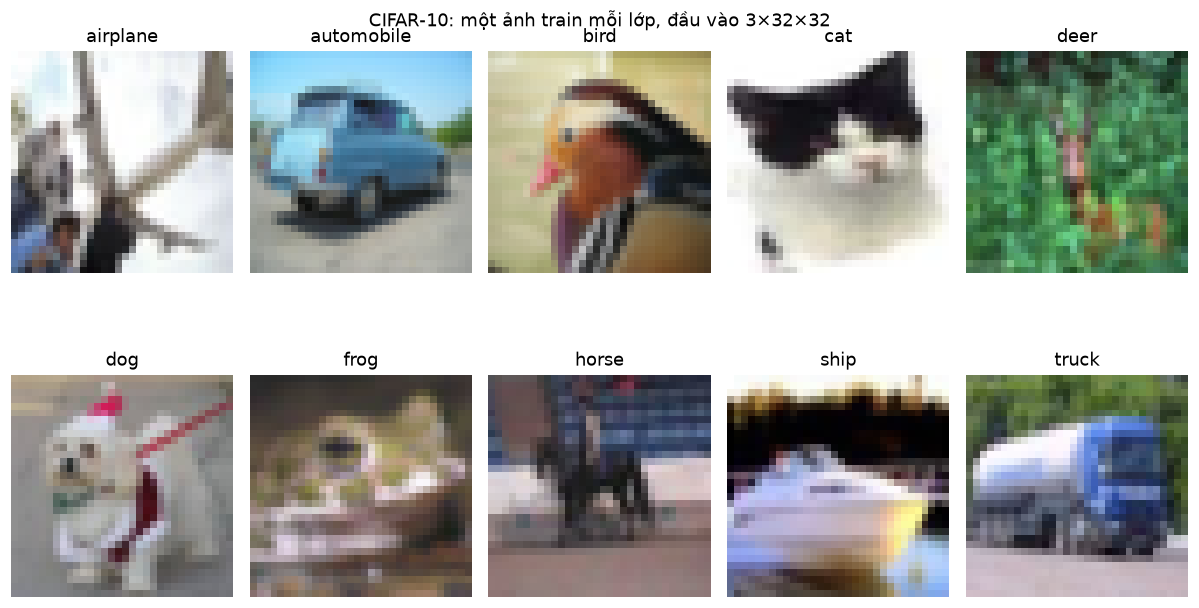

In [3]:
# Dùng lại đúng cách xáo trộn và chia theo lớp của sample_by_class() trong Bài 5.
def sample_by_class(y, n_train, n_val, seed=42):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for label in np.unique(y):
        ids = np.where(y == label)[0]
        rng.shuffle(ids)
        assert len(ids) >= n_train + n_val
        tr.extend(ids[:n_train])
        va.extend(ids[n_train:n_train+n_val])
        te.extend(ids[n_train+n_val:])
    return np.array(tr), np.array(va), np.array(te)

it, iv, ie = sample_by_class(labels, N_TRAIN_PER_CLASS, N_VAL_PER_CLASS, seed=SEED)
assert not set(it) & set(iv) and not set(it) & set(ie) and not set(iv) & set(ie)
assert len(it) + len(iv) + len(ie) == len(labels)

def rgb_tensor(indices):
    return torch.tensor(imgs[indices].transpose(0, 3, 1, 2), dtype=torch.float32) / 255.0

X_train, X_val, X_test = [rgb_tensor(idx) for idx in (it, iv, ie)]
y_train, y_val, y_test = [torch.tensor(labels[idx], dtype=torch.long) for idx in (it, iv, ie)]
mu = float(X_train.mean())
sigma = float(X_train.std().clamp_min(1e-6))
split_table = pd.DataFrame({"class": CLASS_NAMES,
    "train": torch.bincount(y_train, minlength=10).tolist(),
    "validation": torch.bincount(y_val, minlength=10).tolist(),
    "test_noi_bo": torch.bincount(y_test, minlength=10).tolist()})
assert split_table["train"].eq(N_TRAIN_PER_CLASS).all()
assert split_table["validation"].eq(N_VAL_PER_CLASS).all()
assert split_table["test_noi_bo"].eq(N_TEST_PER_CLASS).all()
print(f"Train/Validation/Test nội bộ: {len(it)}/{len(iv)}/{len(ie)}")
print(f"Input CNN: {tuple(X_train.shape)}; mean train = {mu:.6f}; std train = {sigma:.6f}")
display(split_table)
split_table.to_csv(RESULT_DIR / "phan_chia_du_lieu.csv", index=False)
split_rows = []
for split_name, indices in [("train", it), ("validation", iv), ("test_noi_bo", ie)]:
    split_rows.append(pd.DataFrame({"image_id": labels_df.iloc[indices]["id"].to_numpy(),
                                    "split": split_name, "label": labels[indices]}))
pd.concat(split_rows, ignore_index=True).to_csv(RESULT_DIR / "danh_sach_chia_du_lieu.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(11, 5.6))
for c, ax in enumerate(axes.flat):
    idx = int((y_train == c).nonzero(as_tuple=True)[0][0])
    ax.imshow(X_train[idx].permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: một ảnh train mỗi lớp, đầu vào 3×32×32")
plt.tight_layout()
plt.subplots_adjust(hspace=0.45)
plt.show()

## BT2. Dataset, augmentation và DataLoader

Giữ nguyên `ImageTensorDataset` và `loader` của bài mẫu. Các phép `RandomAffine`
(xoay tối đa 10°, dịch 7%, tỷ lệ 0,95–1,05) và `ColorJitter` (sáng/tương phản 0,15)
chỉ áp dụng cho train của E3, E4, M1, M2, M3. Các mô hình đều dùng cùng một phép chia.
Validation, test và train sạch không được tăng cường ảnh.

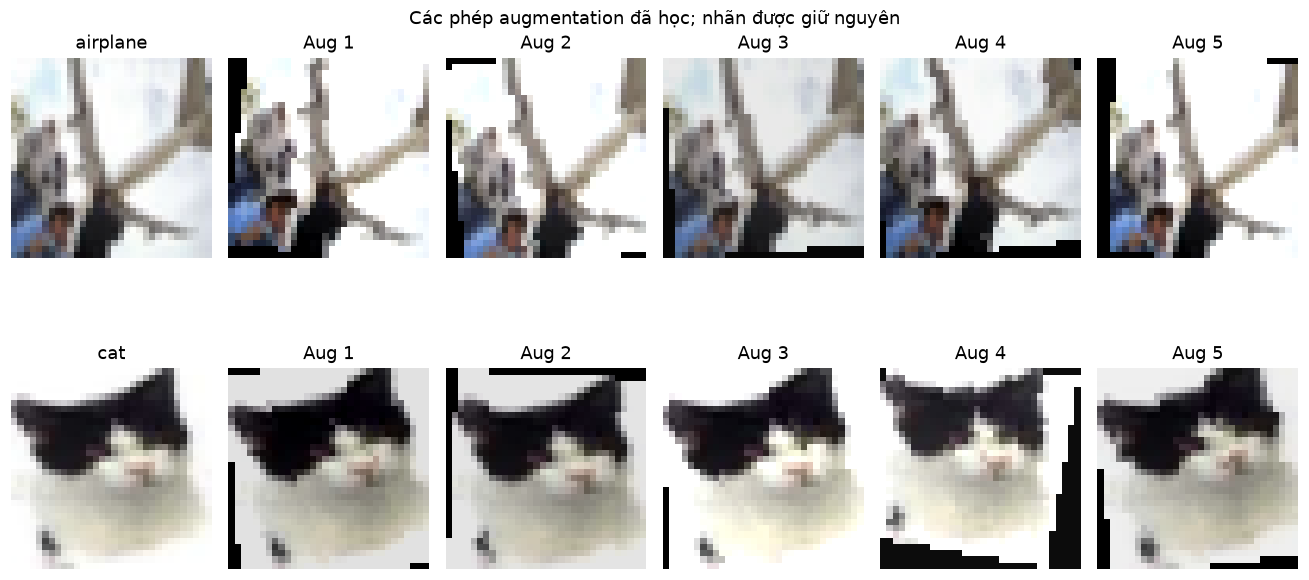

Mini-batch: (64, 3, 32, 32) | nhãn: (64,)


In [4]:
class ImageTensorDataset(Dataset):
    def __init__(self, x, y, augment=False):
        self.x, self.y = x, y
        self.augment = augment
        self.augmenter = transforms.Compose([
            transforms.RandomAffine(degrees=10, translate=(0.07, 0.07), scale=(0.95, 1.05)),
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
        ])
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        image = self.x[idx]
        if self.augment: image = self.augmenter(image).clamp(0, 1)
        image = (image - mu) / sigma
        return image, self.y[idx]

def loader(x, y, train=False, augment=False, batch_size=BATCH_SIZE):
    return DataLoader(ImageTensorDataset(x, y, augment=augment),
                      batch_size=batch_size, shuffle=train, num_workers=0)

train_clean_loader = loader(X_train, y_train, train=False)
train_plain_loader = loader(X_train, y_train, train=True)
train_aug_loader   = loader(X_train, y_train, train=True, augment=True)
val_loader        = loader(X_val, y_val)
test_loader       = loader(X_test, y_test, batch_size=128)


seed_all()
fig, axes = plt.subplots(2, 6, figsize=(12, 5.4))
for row, class_id in enumerate([0, 3]):
    idx = int((y_train == class_id).nonzero(as_tuple=True)[0][0])
    original_image = X_train[idx]
    axes[row, 0].imshow(original_image.permute(1, 2, 0))
    axes[row, 0].set_title(CLASS_NAMES[class_id])
    for col in range(1, 6):
        aug_image = train_aug_loader.dataset.augmenter(original_image).clamp(0, 1)
        axes[row, col].imshow(aug_image.permute(1, 2, 0))
        axes[row, col].set_title(f"Aug {col}")
    for ax in axes[row]:
        ax.axis("off")
plt.suptitle("Các phép augmentation đã học; nhãn được giữ nguyên")
plt.tight_layout()
plt.subplots_adjust(hspace=0.45)
plt.show()
xb, yb = next(iter(train_plain_loader))
print("Mini-batch:", tuple(xb.shape), "| nhãn:", tuple(yb.shape))

**Cơ chế và chế độ chạy:** Augmentation thay đổi ảnh đầu vào; Dropout làm ngẫu nhiên
kích hoạt khi `train()` và được tắt khi `eval()`. AdamW weight decay điều chỉnh độ lớn trọng số
theo cơ chế tách khỏi gradient của loss; không đồng nhất với cộng trực tiếp một hạng L2 vào loss.
BatchNorm dùng thống kê mini-batch khi train và running statistics khi eval.
Do đó `evaluate()` phải dùng `model.eval()` cùng chế độ không tính gradient.
Các cơ chế này khác nhau, không bảo đảm luôn làm tăng accuracy trong mọi cấu hình.

## BT3. Áp dụng các kiến trúc đã học cho ảnh RGB

LeNet giữ nguyên chuỗi kích thước: `32 → 28 → 14 → 10 → 5`.
Số đặc trưng sau Flatten vẫn là `16 × 5 × 5 = 400`; lớp cuối vẫn có 10 logits.
Chỉ đổi `in_channels` của Conv2d đầu tiên thành 3 trong cả bốn mạng.
Không đặt Softmax trước CrossEntropyLoss.

VGG-tiny lặp các convolution 3×3; Inception-tiny nối bốn nhánh theo chiều kênh;
ResNet-tiny cộng nhánh residual với nhánh skip, dùng phép chiếu 1×1 khi cần đổi kích thước.

### Công thức kích thước trong bài 

Với Conv2d, áp dụng riêng cho chiều cao và chiều rộng. $K$ là kernel, $S$ là stride,
$P$ là padding, $D$ là dilation; $N$ là số ảnh và $C$ là số kênh:

$$H_{out}=\left\lfloor\frac{H_{in}+2P-D(K-1)-1}{S}+1\right\rfloor.$$

Pooling thông dụng có $D=1$, `ceil_mode=False` dùng cùng công thức cho kích thước không gian,
giữ nguyên số kênh. Activation (ReLU/Tanh/Sigmoid), BatchNorm và Dropout/Dropout2d giữ nguyên shape.
Các thí nghiệm sử dụng Tanh hoặc ReLU và các lớp Dropout đúng như cấu hình trong bài mẫu.
Flatten biến $(N,C,H,W)$ thành $(N,C\times H\times W)$; Linear biến $(N,F_{in})$ thành $(N,F_{out})$.
Global average pooling biến $(N,C,H,W)$ thành $(N,C,1,1)$.

Với LeNet RGB: Conv đầu có $K=5,S=1,P=0,D=1$ nên $32-5+1=28$;
pool $K=2,S=2$ cho $14$; conv thứ hai cho $10$; pool cho $5$.
Sau Flatten có $16\times5\times5=400$ đặc trưng, qua Linear $400\to120\to84\to10$.
Số kênh RGB chỉ làm đổi `in_channels` của conv đầu, không đổi phép tính kích thước không gian.


In [5]:
class LeNet(nn.Module):
    def __init__(self, activation="tanh", pool="avg", batchnorm=False, dropout=0.0, n_classes=10):
        super().__init__()
        make_act = nn.Tanh if activation == "tanh" else nn.ReLU
        make_pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.features = nn.Sequential(
            nn.Conv2d(3, 6, kernel_size=5),
            nn.BatchNorm2d(6) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.BatchNorm2d(16) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), make_act(), nn.Dropout(dropout),
            nn.Linear(120, 84), make_act(), nn.Dropout(dropout), nn.Linear(84, n_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))  # trả logits, KHÔNG softmax trước CrossEntropyLoss

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline = LeNet()
with torch.no_grad():
    out = baseline(torch.zeros(4, 3, 32, 32))
print('LeNet output:', tuple(out.shape), '| tham số:', f'{count_params(baseline):,}')
print('LeNet classifier:', baseline.classifier)

LeNet output: (4, 10) | tham số: 62,006
LeNet classifier: Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=400, out_features=120, bias=True)
  (2): Tanh()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=120, out_features=84, bias=True)
  (5): Tanh()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=84, out_features=10, bias=True)
)


In [6]:
def vgg_block(cin, cout, nconv=2):
    layers = []
    for j in range(nconv):
        layers += [nn.Conv2d(cin if j == 0 else cout, cout, 3, padding=1, bias=False),
                   nn.BatchNorm2d(cout), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2))

class VGGTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(vgg_block(3,16), vgg_block(16,32), vgg_block(32,64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64,64), nn.ReLU(), nn.Dropout(.25),
                                  nn.Linear(64,n_classes))
    def forward(self,x): return self.head(self.features(x))

class InceptionBlock(nn.Module):
    def __init__(self, cin, branch_channels):
        super().__init__()
        c = branch_channels
        # BatchNorm sau từng convolution để các nhánh có thang kích hoạt ổn định.
        def cbr(a, b, k, p=0):
            return [nn.Conv2d(a,b,k,padding=p,bias=False),nn.BatchNorm2d(b),nn.ReLU()]
        self.b1 = nn.Sequential(*cbr(cin,c,1))
        self.b3 = nn.Sequential(*cbr(cin,c,1),*cbr(c,c,3,p=1))
        self.b5 = nn.Sequential(*cbr(cin,c,1),*cbr(c,c,5,p=2))
        self.bp = nn.Sequential(nn.MaxPool2d(3,stride=1,padding=1),*cbr(cin,c,1))
    def forward(self,x):
        return torch.cat([self.b1(x),self.b3(x),self.b5(x),self.bp(x)],dim=1)

class InceptionTiny(nn.Module):
    def __init__(self,n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1),nn.BatchNorm2d(16),nn.ReLU(),
            InceptionBlock(16,8),nn.MaxPool2d(2),
            InceptionBlock(32,16),nn.MaxPool2d(2),
            InceptionBlock(64,16))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.25),nn.Linear(64,n_classes))
    def forward(self,x):return self.head(self.features(x))

class ResidualBlock(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__()
        self.residual = nn.Sequential(
            nn.Conv2d(cin,cout,3,stride=stride,padding=1,bias=False),nn.BatchNorm2d(cout),nn.ReLU(),
            nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if cin==cout and stride==1 else
                     nn.Sequential(nn.Conv2d(cin,cout,1,stride=stride,bias=False),nn.BatchNorm2d(cout)))
        self.act = nn.ReLU()
    def forward(self,x): return self.act(self.residual(x)+self.skip(x))

class ResNetTiny(nn.Module):
    def __init__(self,n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3,16,3,padding=1,bias=False),nn.BatchNorm2d(16),nn.ReLU())
        self.blocks = nn.Sequential(ResidualBlock(16,16),ResidualBlock(16,32,stride=2),
                                    ResidualBlock(32,32),ResidualBlock(32,64,stride=2),ResidualBlock(64,64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(64,n_classes))
    def forward(self,x): return self.head(self.blocks(self.stem(x)))

models_for_shape = {"LeNet":LeNet(),"VGG-tiny":VGGTiny(),
                    "Inception-tiny":InceptionTiny(),"ResNet-tiny":ResNetTiny()}
shape_rows = []
for name, net in models_for_shape.items():
    with torch.no_grad(): output = net.eval()(torch.zeros(2,3,32,32))
    shape_rows.append(dict(model=name, logits_shape=str(tuple(output.shape)),
                           params=count_params(net)))
display(pd.DataFrame(shape_rows))
assert all(row["logits_shape"] == "(2, 10)" for row in shape_rows)

,model,logits_shape,params
0,LeNet,"(2, 10)",62006
1,VGG-tiny,"(2, 10)",77114
2,Inception-tiny,"(2, 10)",27850
3,ResNet-tiny,"(2, 10)",170586


### Bảng kích thước qua các lớp/khối và đối chiếu các nhánh

Các bảng dưới được kiểm tra bằng forward với tensor giả `(2, 3, 32, 32)`, không huấn luyện và không dùng tập test. VGG được liệt kê theo khối: các Conv 3×3, padding 1 giữ nguyên H/W; MaxPool cuối khối giảm mỗi chiều còn một nửa.

In [26]:
# Áp dụng cách kiểm tra tensor trong bài giảng, với batch giả gồm 2 ảnh RGB.
shape_models = {"LeNet": LeNet(), "VGG-tiny": VGGTiny(),
                "Inception-tiny": InceptionTiny(), "ResNet-tiny": ResNetTiny()}
dimension_rows, branch_rows = [], []
with torch.no_grad():
    for model_name, model in shape_models.items():
        model.eval()
        x = torch.zeros(2, 3, 32, 32)
        dimension_rows.append({"model": model_name, "stage": "Input", "shape": str(tuple(x.shape))})
        if model_name == "LeNet":
            groups = [("features", model.features), ("classifier", model.classifier)]
        elif model_name == "ResNet-tiny":
            groups = [("stem", model.stem), ("blocks", model.blocks), ("head", model.head)]
        else:
            groups = [("features", model.features), ("head", model.head)]
        for group_name, layers in groups:
            for layer_id, layer in enumerate(layers):
                stage = f"{group_name}.{layer_id}: {type(layer).__name__}"
                if isinstance(layer, InceptionBlock):
                    shapes = [tuple(branch(x).shape) for branch in [layer.b1, layer.b3, layer.b5, layer.bp]]
                    assert len({s[2:] for s in shapes}) == 1
                    branch_rows.append({"model": model_name, "stage": stage,
                        "nhanh_1x1": str(shapes[0]), "nhanh_3x3": str(shapes[1]),
                        "nhanh_5x5": str(shapes[2]), "nhanh_pool": str(shapes[3]),
                        "ghep_theo_kenh": str((2, sum(s[1] for s in shapes), *shapes[0][2:]))})
                if isinstance(layer, ResidualBlock):
                    residual_shape, skip_shape = tuple(layer.residual(x).shape), tuple(layer.skip(x).shape)
                    assert residual_shape == skip_shape
                    branch_rows.append({"model": model_name, "stage": stage,
                        "residual": str(residual_shape), "skip": str(skip_shape),
                        "phep_chieu_1x1": not isinstance(layer.skip, nn.Identity)})
                x = layer(x)
                dimension_rows.append({"model": model_name, "stage": stage, "shape": str(tuple(x.shape))})
        assert tuple(x.shape) == (2, 10)
dimension_table = pd.DataFrame(dimension_rows)
branch_table = pd.DataFrame(branch_rows)
for model_name in shape_models:
    print("KÍCH THƯỚC QUA CÁC LỚP:", model_name)
    display(dimension_table.loc[dimension_table.model == model_name, ["stage", "shape"]].reset_index(drop=True))
print("ĐỐI CHIẾU CÁC NHÁNH INCEPTION:")
display(branch_table.loc[branch_table.model == "Inception-tiny"].dropna(axis=1, how="all"))
print("ĐỐI CHIẾU RESIDUAL VÀ SKIP:")
display(branch_table.loc[branch_table.model == "ResNet-tiny"].dropna(axis=1, how="all"))
dimension_table.to_csv(RESULT_DIR / "kich_thuoc_qua_cac_lop.csv", index=False)
branch_table.to_csv(RESULT_DIR / "kich_thuoc_cac_nhanh.csv", index=False)

KÍCH THƯỚC QUA CÁC LỚP: LeNet


,stage,shape
0,Input,"(2, 3, 32, 32)"
1,features.0: Conv2d,"(2, 6, 28, 28)"
2,features.1: Identity,"(2, 6, 28, 28)"
3,features.2: Tanh,"(2, 6, 28, 28)"
4,features.3: AvgPool2d,"(2, 6, 14, 14)"
5,features.4: Conv2d,"(2, 16, 10, 10)"
6,features.5: Identity,"(2, 16, 10, 10)"
7,features.6: Tanh,"(2, 16, 10, 10)"
8,features.7: AvgPool2d,"(2, 16, 5, 5)"
9,classifier.0: Flatten,"(2, 400)"


KÍCH THƯỚC QUA CÁC LỚP: VGG-tiny


,stage,shape
0,Input,"(2, 3, 32, 32)"
1,features.0: Sequential,"(2, 16, 16, 16)"
2,features.1: Sequential,"(2, 32, 8, 8)"
3,features.2: Sequential,"(2, 64, 4, 4)"
4,head.0: AdaptiveAvgPool2d,"(2, 64, 1, 1)"
5,head.1: Flatten,"(2, 64)"
6,head.2: Linear,"(2, 64)"
7,head.3: ReLU,"(2, 64)"
8,head.4: Dropout,"(2, 64)"
9,head.5: Linear,"(2, 10)"


KÍCH THƯỚC QUA CÁC LỚP: Inception-tiny


,stage,shape
0,Input,"(2, 3, 32, 32)"
1,features.0: Conv2d,"(2, 16, 32, 32)"
2,features.1: BatchNorm2d,"(2, 16, 32, 32)"
3,features.2: ReLU,"(2, 16, 32, 32)"
4,features.3: InceptionBlock,"(2, 32, 32, 32)"
5,features.4: MaxPool2d,"(2, 32, 16, 16)"
6,features.5: InceptionBlock,"(2, 64, 16, 16)"
7,features.6: MaxPool2d,"(2, 64, 8, 8)"
8,features.7: InceptionBlock,"(2, 64, 8, 8)"
9,head.0: AdaptiveAvgPool2d,"(2, 64, 1, 1)"


... (2 outputs left out)

ĐỐI CHIẾU CÁC NHÁNH INCEPTION:


,model,stage,nhanh_1x1,nhanh_3x3,nhanh_5x5,nhanh_pool,ghep_theo_kenh
0,Inception-tiny,features.3: InceptionBlock,"(2, 8, 32, 32)","(2, 8, 32, 32)","(2, 8, 32, 32)","(2, 8, 32, 32)","(2, 32, 32, 32)"
1,Inception-tiny,features.5: InceptionBlock,"(2, 16, 16, 16)","(2, 16, 16, 16)","(2, 16, 16, 16)","(2, 16, 16, 16)","(2, 64, 16, 16)"
2,Inception-tiny,features.7: InceptionBlock,"(2, 16, 8, 8)","(2, 16, 8, 8)","(2, 16, 8, 8)","(2, 16, 8, 8)","(2, 64, 8, 8)"


ĐỐI CHIẾU RESIDUAL VÀ SKIP:


,model,stage,residual,skip,phep_chieu_1x1
3,ResNet-tiny,blocks.0: ResidualBlock,"(2, 16, 32, 32)","(2, 16, 32, 32)",False
4,ResNet-tiny,blocks.1: ResidualBlock,"(2, 32, 16, 16)","(2, 32, 16, 16)",True
5,ResNet-tiny,blocks.2: ResidualBlock,"(2, 32, 16, 16)","(2, 32, 16, 16)",False
6,ResNet-tiny,blocks.3: ResidualBlock,"(2, 64, 8, 8)","(2, 64, 8, 8)",True
7,ResNet-tiny,blocks.4: ResidualBlock,"(2, 64, 8, 8)","(2, 64, 8, 8)",False


## BT4. Dùng lại các hàm của Bài 5

Ba hàm `train_one_epoch`, `evaluate`, `test_model` và engine `fit_model`/`run_experiment`
được chép nguyên từ bài. Chỉ đổi dữ liệu và số kênh đầu vào; mọi thí nghiệm dùng AdamW,
learning rate 0,001, batch size 64, 16 epoch, seed 42. Loss được cộng theo số mẫu.

`opt_loss` là loss trong quá trình tối ưu (có thể gồm augmentation/Dropout), còn
`train_loss` là đánh giá lại train sạch ở chế độ eval. Checkpoint có validation loss thấp
nhất được phục hồi trước khi tính metrics, vẽ ảnh sai và đưa vào bảng tổng hợp.

In [7]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    """Huấn luyện đúng 1 epoch; tái dùng cho MLP/CNN/RNN phân loại.

    Args:
        model: nn.Module, đầu ra là logits [batch, n_classes].
        dataloader: iterable cung cấp (images/features, labels).
        optimizer: torch.optim.Optimizer.
        criterion: hàm loss (ví dụ nn.CrossEntropyLoss()).
        device: torch.device("cpu"/"cuda").
    Returns:
        dict(loss, accuracy, n_samples); loss/accuracy trung bình theo SỐ MẪU.
    """
    model.train()                      # bật Dropout và train-mode của BatchNorm
    total_loss = 0.0
    n_correct = 0
    n_samples = 0

    for x, y in dataloader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)              # forward
        loss = criterion(logits, y)
        loss.backward()                # backward: tính gradient
        optimizer.step()               # cập nhật tham số

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (logits.argmax(dim=1) == y).sum().item()
        n_samples += batch_size

    if n_samples == 0:
        raise ValueError("Train DataLoader không được rỗng")
    return {"loss": total_loss / n_samples,
            "accuracy": n_correct / n_samples,
            "n_samples": n_samples}

print("Đã khai báo train_one_epoch(model, dataloader, optimizer, criterion, device)")

Đã khai báo train_one_epoch(model, dataloader, optimizer, criterion, device)


In [8]:
@torch.inference_mode()
def evaluate(model, dataloader, criterion, device, return_predictions=False):
    """Đánh giá không cập nhật trọng số; có thể trả nhãn để phục vụ test.

    Dùng cho: monitor train sạch, validation, và lõi tính toán của test_model.
    Không lựa chọn mô hình bằng kết quả test.
    """
    model.eval()                       # tắt Dropout; BatchNorm dùng running stats
    total_loss = 0.0
    n_correct = 0
    n_samples = 0
    y_true, y_pred = [], []

    for x, y in dataloader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        preds = logits.argmax(dim=1)

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (preds == y).sum().item()
        n_samples += batch_size
        if return_predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    if n_samples == 0:
        raise ValueError("Eval DataLoader không được rỗng")
    metrics = {"loss": total_loss / n_samples,
               "accuracy": n_correct / n_samples,
               "n_samples": n_samples}
    if return_predictions:
        metrics["y_true"] = np.asarray(y_true, dtype=np.int64)
        metrics["y_pred"] = np.asarray(y_pred, dtype=np.int64)
    return metrics

print("Đã khai báo evaluate(model, dataloader, criterion, device, return_predictions=False)")

Đã khai báo evaluate(model, dataloader, criterion, device, return_predictions=False)


In [9]:
def test_model(model, dataloader, criterion, device, class_names):
    """Đánh giá CUỐI trên test set; không huấn luyện/điều chỉnh hyperparameter.

    Tái sử dụng evaluate() để có cùng công thức loss/accuracy với validation.
    Trả về dict gồm loss, accuracy, confusion matrix, report, nhãn thật/dự đoán.
    """
    raw = evaluate(model, dataloader, criterion, device, return_predictions=True)
    labels = list(range(len(class_names)))
    cm = confusion_matrix(raw["y_true"], raw["y_pred"], labels=labels)
    report = classification_report(raw["y_true"], raw["y_pred"],
                                   labels=labels, target_names=class_names,
                                   zero_division=0)
    return {"loss": raw["loss"], "accuracy": raw["accuracy"],
            "n_samples": raw["n_samples"],
            "y_true": raw["y_true"], "y_pred": raw["y_pred"],
            "confusion_matrix": cm, "classification_report": report}

print("Đã khai báo test_model(model, dataloader, criterion, device, class_names)")

Đã khai báo test_model(model, dataloader, criterion, device, class_names)


In [10]:
criterion = nn.CrossEntropyLoss()
RESULTS, HISTORIES, BEST_MODELS = [], {}, {}
VAL_ANALYSES = {}  # chỉ chứa mẫu và xác suất trên validation, KHÔNG chứa test


def fit_model(model, train_loader, train_monitor_loader, val_loader,
              optimizer, criterion, device, epochs, run_name):
    """Vòng lặp epochs dùng chung: train, eval, checkpoint theo val loss.

    In TẤT CẢ epoch và trả (model_best, history_dataframe, best_epoch).
    """
    history = []
    best_val_loss, best_state, best_epoch = float("inf"), None, 0
    print("epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best")
    print("-" * 78)

    for epoch in range(1, epochs + 1):
        opt = train_one_epoch(model, train_loader, optimizer, criterion, device)
        train = evaluate(model, train_monitor_loader, criterion, device)
        val = evaluate(model, val_loader, criterion, device)
        history.append({"epoch": epoch, "opt_loss": opt["loss"],
                        "opt_acc": opt["accuracy"],
                        "train_loss": train["loss"], "train_acc": train["accuracy"],
                        "val_loss": val["loss"], "val_acc": val["accuracy"]})

        improved = val["loss"] < best_val_loss
        if improved:
            best_val_loss = val["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        print(f"{epoch:02d}/{epochs:02d} | {opt['loss']:.4f}   | "
              f"{train['loss']:.4f}     | {train['accuracy']:.2%}  | "
              f"{val['loss']:.4f}   | {val['accuracy']:.2%}  | {'*' if improved else ''}",
              flush=True)

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


def plot_single_run(name, history):
    """Mỗi thí nghiệm có learning curves RIÊNG, hiển thị sau log epoch."""
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    axes[0].plot(history.epoch, history.train_acc * 100, label="Train sạch")
    axes[0].plot(history.epoch, history.val_acc * 100, label="Validation")
    axes[1].plot(history.epoch, history.train_loss, label="Train sạch")
    axes[1].plot(history.epoch, history.val_loss, label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend()
    fig.suptitle(f"Learning curves: {name}", weight="bold")
    plt.tight_layout()
    plt.show()


def run_experiment(name, model_factory, use_aug=False, wd=0.0,
                   epochs=EPOCHS, seed=SEED, show_plot=True):
    """Tạo mô hình mới, train/eval cùng engine; KHÔNG dùng test set."""
    if name in HISTORIES:
        raise ValueError(f"Tên thí nghiệm đã tồn tại: {name}. Run all để làm mới.")
    seed_all(seed)
    model = model_factory().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=wd)
    dl_train = train_aug_loader if use_aug else train_plain_loader
    start = time.perf_counter()
    print(f"\n=== {name} ===")
    print(f"params={count_params(model):,} | augmentation={use_aug} | "
          f"weight_decay={wd:g} | lr={LR} | epochs={epochs}")
    model, history, best_epoch = fit_model(
        model, dl_train, train_clean_loader, val_loader,
        optimizer, criterion, DEVICE, epochs, run_name=name)
    seconds = time.perf_counter() - start
    train = evaluate(model, train_clean_loader, criterion, DEVICE)
    val = evaluate(model, val_loader, criterion, DEVICE)
    row = {"model": name, "parameters": count_params(model),
           "best_epoch": best_epoch, "train_acc": train["accuracy"],
           "val_acc": val["accuracy"], "val_loss": val["loss"],
           "gap": train["accuracy"] - val["accuracy"], "seconds": round(seconds, 2)}
    HISTORIES[name] = history
    BEST_MODELS[name] = copy.deepcopy(model).cpu()   # không chiếm GPU giữa các runs
    RESULTS.append(row)
    print(f"\nCHECKPOINT được chọn: epoch {best_epoch:02d} | "
          f"train_acc={train['accuracy']:.2%} | val_acc={val['accuracy']:.2%} | "
          f"val_loss={val['loss']:.4f} | gap={row['gap']:+.2%}")
    if show_plot:
        plot_single_run(name, history)

    # Phân tích lỗi trên VALIDATION tại checkpoint tốt nhất của thí nghiệm.
    analysis = analyze_validation_errors(
        model, val_loader, CLASS_NAMES, DEVICE,
        mean=mu, std=sigma, run_name=name, max_examples=6, show_plot=show_plot)
    row["val_errors"] = analysis["n_errors"]
    VAL_ANALYSES[name] = analysis
    return row

print("Đã khai báo fit_model()/run_experiment(): mỗi thí nghiệm có log, curves và phân tích lỗi validation.")

Đã khai báo fit_model()/run_experiment(): mỗi thí nghiệm có log, curves và phân tích lỗi validation.


In [11]:
@torch.inference_mode()
def collect_validation_predictions(model, dataloader, device):
    """Thu chi tiết dự đoán trên validation (DataLoader không shuffle/augment).

    Args:
        model: mô hình trả logits có shape [batch_size, n_classes].
        dataloader: DataLoader validation, shuffle=False; trả (images, labels).
        device: CPU hoặc GPU.
    Returns:
        details: DataFrame với vị trí mẫu, nhãn thật/dự đoán, confidence,
                 p_true (xác suất nhãn thật) và cột correct.
        images: tensor ảnh ĐÃ CHUẨN HÓA ở CPU, cùng thứ tự với details.
    """
    model.eval()
    records, stored_images = [], []
    sample_index = 0

    for images, labels in dataloader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)
        p_true = probabilities.gather(1, labels.to(device).unsqueeze(1)).squeeze(1)

        labels_cpu = labels.cpu().tolist()
        preds_cpu = predictions.cpu().tolist()
        confidences = confidence.cpu().tolist()
        p_true_values = p_true.cpu().tolist()
        stored_images.append(images.detach().cpu().clone())

        for true_label, pred_label, score, true_score in zip(
            labels_cpu, preds_cpu, confidences, p_true_values
        ):
            records.append({
                "sample_index": sample_index,
                "true_label": int(true_label),
                "pred_label": int(pred_label),
                "confidence": float(score),
                "p_true": float(true_score),
                "correct": int(true_label) == int(pred_label),
            })
            sample_index += 1

    if not records:
        raise ValueError("DataLoader validation không được rỗng")
    return pd.DataFrame(records), torch.cat(stored_images, dim=0)


def plot_misclassified_images(details, images, class_names, *,
                              mean=0.0, std=1.0, max_examples=6,
                              hardest_first=True, title="Validation"):
    """Vẽ mẫu sai theo confidence; chỉ dùng predictions của validation.

    hardest_first=True: ưu tiên sai nhưng tự tin cao (high-confidence errors).
    hardest_first=False: ưu tiên sai có confidence thấp (uncertain errors).
    """
    wrong = details.loc[~details["correct"]].sort_values(
        "confidence", ascending=not hardest_first).head(max_examples)
    if wrong.empty:
        print("Không có mẫu validation dự đoán sai để hiển thị.")
        return

    ncols = min(3, len(wrong))
    nrows = (len(wrong) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")

    for ax, sample in zip(axes.ravel(), wrong.itertuples(index=False)):
        index = int(sample.sample_index)
        image = (images[index] * std + mean).clamp(0, 1)
        if image.shape[0] == 1:
            ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
        elif image.shape[0] == 3:
            ax.imshow(image.permute(1, 2, 0))
        else:
            raise ValueError("Ví dụ minh họa hiện hỗ trợ ảnh 1 hoặc 3 kênh")
        ax.set_title(
            f"Mẫu #{index} | Thật: {class_names[sample.true_label]} "
            f"→ Dự đoán: {class_names[sample.pred_label]}\n"
            f"Confidence: {sample.confidence:.1%} | P(nhãn thật): {sample.p_true:.1%}",
            fontsize=9, color="firebrick")
    label = "Sai nhưng rất tự tin" if hardest_first else "Sai với confidence thấp"
    fig.suptitle(f"{title} — {label} (VALIDATION)", fontsize=12, weight="bold")
    plt.tight_layout()
    plt.show()


def analyze_validation_errors(model, dataloader, class_names, device, *,
                              mean=0.0, std=1.0, run_name="Model",
                              max_examples=6, show_plot=True):
    """Thống kê và minh họa lỗi validation; không động tới test set."""
    details, images = collect_validation_predictions(model, dataloader, device)
    wrong = details.loc[~details["correct"]].copy()
    n_total, n_errors = len(details), len(wrong)
    print(f"\n--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — {run_name} ---")
    print(f"Sai {n_errors}/{n_total} mẫu ({n_errors/n_total:.2%}); "
          f"đúng {(n_total-n_errors)/n_total:.2%}.")

    if n_errors:
        pairs = (wrong.groupby(["true_label", "pred_label"])
                 .size().sort_values(ascending=False).head(3))
        print("Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):")
        for (true_id, pred_id), count in pairs.items():
            print(f"  {class_names[true_id]} → {class_names[pred_id]}: {count} mẫu")
        print(f"Confidence trung bình của các mẫu sai: {wrong['confidence'].mean():.2%}")
    else:
        print("Không có cặp nhầm lẫn trong validation tại checkpoint này.")

    if show_plot and n_errors:
        plot_misclassified_images(
            details, images, class_names, mean=mean, std=std,
            max_examples=max_examples, hardest_first=True, title=run_name)

    return {"details": details, "images": images,
            "n_errors": n_errors, "n_total": n_total}

print("Đã khai báo collect_validation_predictions(), "
      "plot_misclassified_images() và analyze_validation_errors().")

Đã khai báo collect_validation_predictions(), plot_misclassified_images() và analyze_validation_errors().


## BT5. Tám thí nghiệm

| Mã | Cấu hình | Augmentation | Weight decay |
|---|---|---|---|
| E0 | LeNet Tanh + AvgPool | Không | 0 |
| E1 | LeNet ReLU + MaxPool | Không | 0 |
| E2 | E1 + Dropout 0,35 | Không | 0,001 |
| E3 | E2 + augmentation | Có | 0,001 |
| E4 | E3 + BatchNorm | Có | 0,001 |
| M1 | VGG-tiny như bài mẫu | Có | 0,001 |
| M2 | Inception-tiny như bài mẫu | Có | 0,001 |
| M3 | ResNet-tiny như bài mẫu | Có | 0,001 |

E0→E1 thay hai yếu tố; E1→E2 cũng thay hai yếu tố. Vì vậy không tách riêng được
hiệu quả của activation/pooling hay Dropout/weight decay. AdamW áp dụng weight decay
tách khỏi cập nhật gradient của loss, đúng cách dùng trong bài mẫu.

### E0. LeNet Tanh + AvgPool: mốc đối chiếu


=== E0 LeNet Tanh+Avg ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7521   | 1.5880     | 43.88%  | 1.6097   | 43.16%  | *
02/16 | 1.5140   | 1.3952     | 50.27%  | 1.4446   | 49.80%  | *
03/16 | 1.3737   | 1.3062     | 53.35%  | 1.3855   | 50.86%  | *
04/16 | 1.2829   | 1.2160     | 56.81%  | 1.3199   | 53.74%  | *
05/16 | 1.2115   | 1.1708     | 58.76%  | 1.3013   | 53.46%  | *
06/16 | 1.1586   | 1.0677     | 62.50%  | 1.2418   | 56.50%  | *
07/16 | 1.1101   | 1.0489     | 62.85%  | 1.2674   | 55.36%  | 
08/16 | 1.0674   | 1.0129     | 64.09%  | 1.2485   | 55.56%  | 
09/16 | 1.0282   | 0.9603     | 66.34%  | 1.2481   | 56.70%  | 
10/16 | 0.9872   | 0.9140     | 67.58%  | 1.2443   | 57.26%  | 
11/16 | 0.9563   | 0.8662     | 69.57%  | 1.2389   | 57.22%  | *
12/16 | 0.9224   | 0.8488     | 70.17%

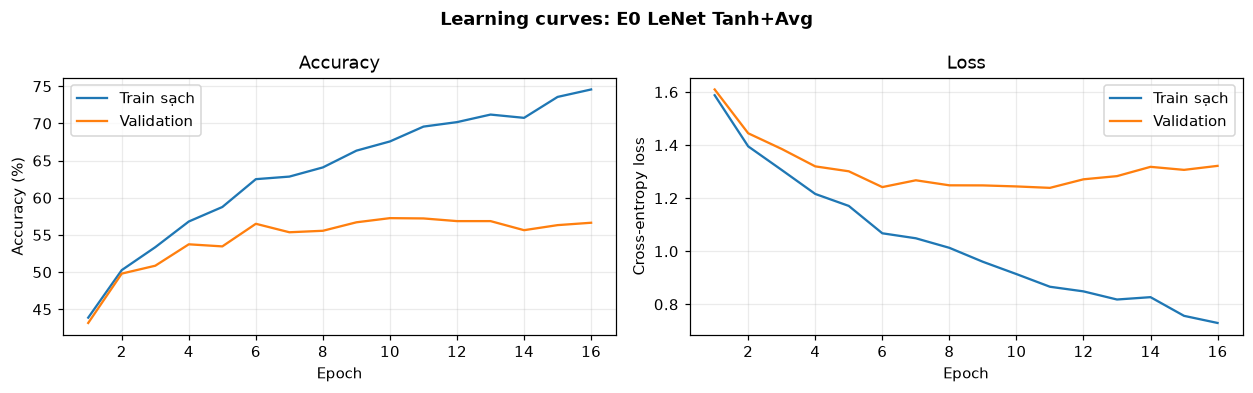


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E0 LeNet Tanh+Avg ---
Sai 2139/5000 mẫu (42.78%); đúng 57.22%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 138 mẫu
  bird → deer: 77 mẫu
  airplane → ship: 72 mẫu
Confidence trung bình của các mẫu sai: 53.22%


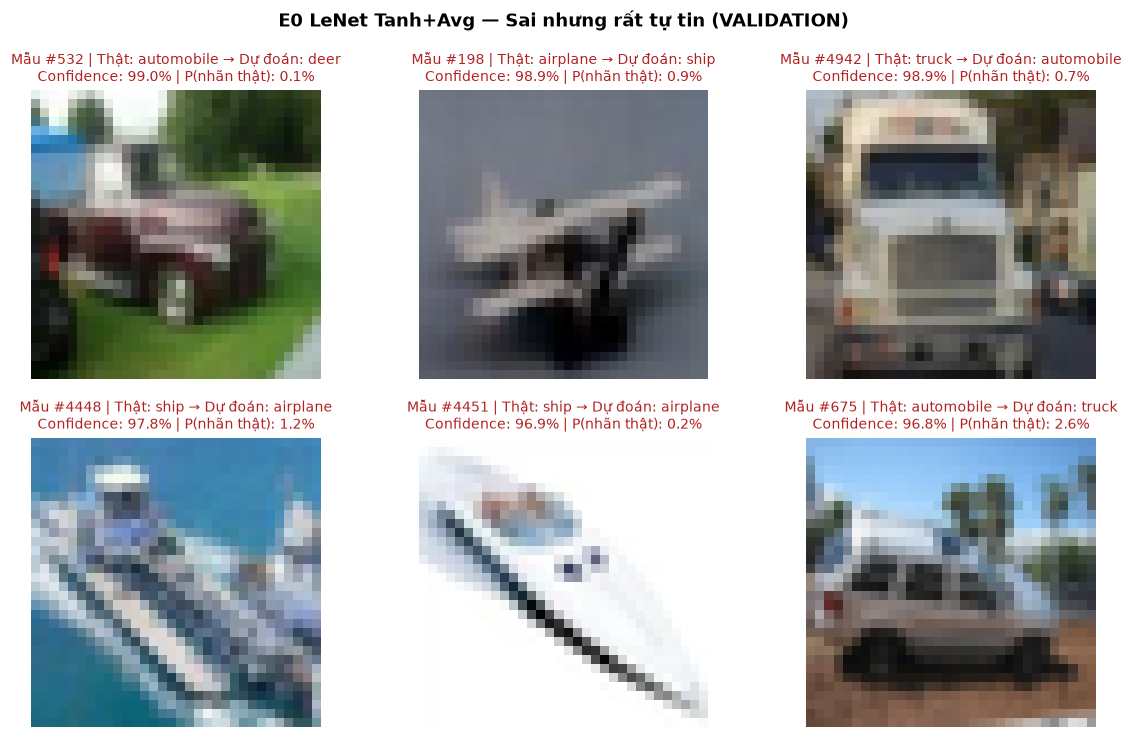

In [12]:
result_E0 = run_experiment(
    "E0 LeNet Tanh+Avg", lambda: LeNet(activation="tanh", pool="avg"), use_aug=False, wd=0.0
)
HISTORIES[result_E0["model"]].to_csv(RESULT_DIR / "lich_su_E0.csv", index=False)
VAL_ANALYSES[result_E0["model"]]["details"].to_csv(RESULT_DIR / "validation_E0.csv", index=False)

**Nhận xét E0 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **11**, train accuracy **69.57%**, validation accuracy **57.22%**, validation loss **1.2389**, gap train–validation **+12.35 điểm phần trăm**.

Mô hình sai **2139/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 138 ảnh; bird → deer: 77 ảnh; airplane → ship: 72 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

Đây là baseline để đối chiếu các thay đổi tiếp theo. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 11 đến epoch 16, train loss từ 0.8662 thành 0.7298, còn validation loss từ 1.2389 thành 1.3218. Train loss tiếp tục giảm trong khi validation loss tăng là dấu hiệu học sát tập train hơn nhưng khả năng tổng quát hóa giảm ở giai đoạn cuối. Vì vậy dùng checkpoint đã chọn thay cho trọng số epoch cuối.

### E1. LeNet ReLU + MaxPool


=== E1 LeNet ReLU+Max ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.6584   | 1.4444     | 47.84%  | 1.4541   | 47.58%  | *
02/16 | 1.3723   | 1.2840     | 53.94%  | 1.3250   | 52.08%  | *
03/16 | 1.2489   | 1.2051     | 56.61%  | 1.2781   | 53.16%  | *
04/16 | 1.1564   | 1.1107     | 60.16%  | 1.1901   | 57.18%  | *
05/16 | 1.0843   | 1.0243     | 63.98%  | 1.1368   | 60.14%  | *
06/16 | 1.0286   | 0.9292     | 67.39%  | 1.0692   | 62.28%  | *
07/16 | 0.9718   | 0.8878     | 68.53%  | 1.0701   | 61.90%  | 
08/16 | 0.9249   | 0.8751     | 68.97%  | 1.0882   | 61.96%  | 
09/16 | 0.8814   | 0.8248     | 71.02%  | 1.0714   | 62.70%  | 
10/16 | 0.8431   | 0.7990     | 71.67%  | 1.0848   | 62.70%  | 
11/16 | 0.8083   | 0.7505     | 73.29%  | 1.0809   | 63.90%  | 
12/16 | 0.7712   | 0.6940     | 75.39% 

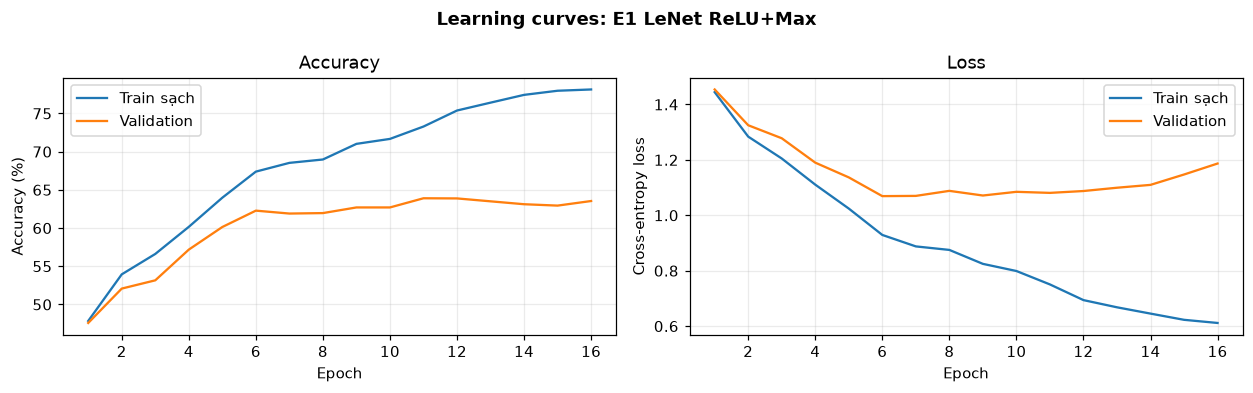


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E1 LeNet ReLU+Max ---
Sai 1886/5000 mẫu (37.72%); đúng 62.28%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 104 mẫu
  cat → dog: 81 mẫu
  truck → automobile: 76 mẫu
Confidence trung bình của các mẫu sai: 49.28%


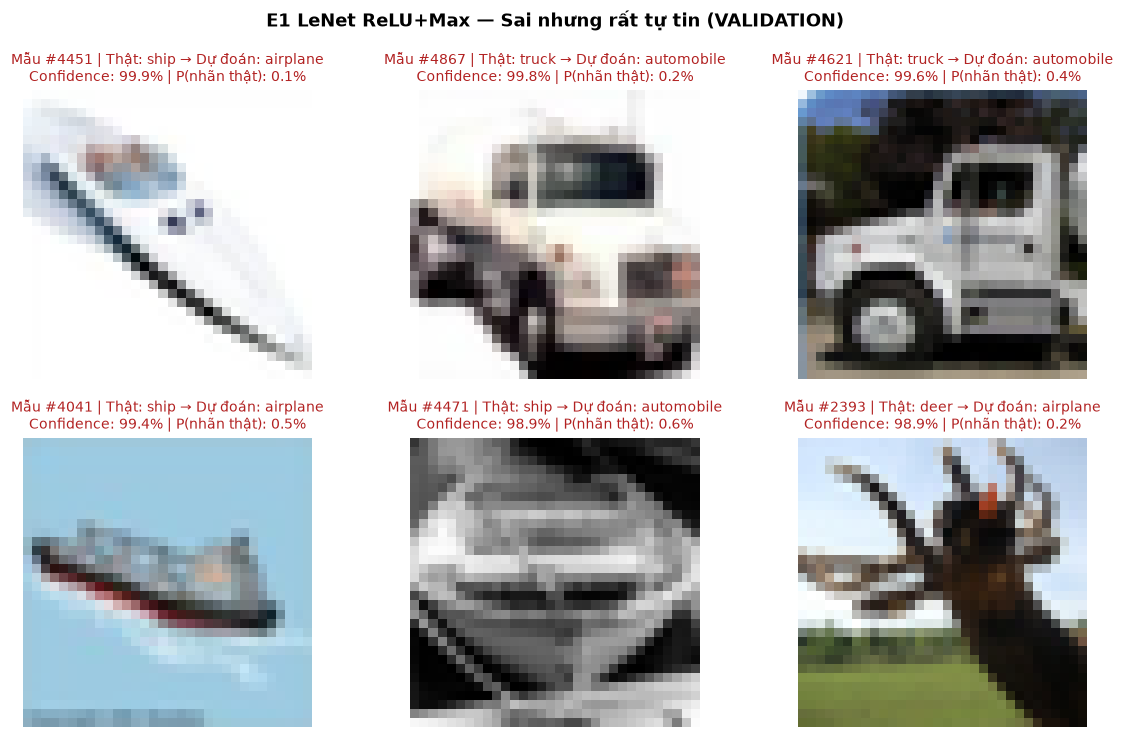

In [13]:
result_E1 = run_experiment(
    "E1 LeNet ReLU+Max", lambda: LeNet(activation="relu", pool="max"), use_aug=False, wd=0.0
)
HISTORIES[result_E1["model"]].to_csv(RESULT_DIR / "lich_su_E1.csv", index=False)
VAL_ANALYSES[result_E1["model"]]["details"].to_csv(RESULT_DIR / "validation_E1.csv", index=False)

**Nhận xét E1 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **6**, train accuracy **67.39%**, validation accuracy **62.28%**, validation loss **1.0692**, gap train–validation **+5.11 điểm phần trăm**. So với E0, validation accuracy thay đổi **+5.06 điểm phần trăm**, validation loss từ **1.2389** thành **1.0692**.

Mô hình sai **1886/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 104 ảnh; cat → dog: 81 ảnh; truck → automobile: 76 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

Thay đồng thời activation và pooling nên không tách được hiệu quả của từng thành phần. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 6 đến epoch 16, train loss từ 0.9292 thành 0.6115, còn validation loss từ 1.0692 thành 1.1869. Train loss tiếp tục giảm trong khi validation loss tăng là dấu hiệu học sát tập train hơn nhưng khả năng tổng quát hóa giảm ở giai đoạn cuối. Vì vậy dùng checkpoint đã chọn thay cho trọng số epoch cuối.

### E2. Thêm Dropout và weight decay


=== E2 LeNet +Dropout+WD ===
params=62,006 | augmentation=False | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7690   | 1.4841     | 45.56%  | 1.4813   | 45.72%  | *
02/16 | 1.4936   | 1.3299     | 52.02%  | 1.3557   | 50.86%  | *
03/16 | 1.3904   | 1.2549     | 54.24%  | 1.2958   | 52.38%  | *
04/16 | 1.3177   | 1.2102     | 56.30%  | 1.2662   | 54.02%  | *
05/16 | 1.2756   | 1.1620     | 58.95%  | 1.2340   | 55.42%  | *
06/16 | 1.2306   | 1.0698     | 61.91%  | 1.1594   | 58.14%  | *
07/16 | 1.1919   | 1.0237     | 63.44%  | 1.1293   | 59.40%  | *
08/16 | 1.1649   | 1.0067     | 64.06%  | 1.1144   | 60.02%  | *
09/16 | 1.1367   | 0.9872     | 65.02%  | 1.1081   | 60.26%  | *
10/16 | 1.1127   | 0.9714     | 65.31%  | 1.1123   | 59.68%  | 
11/16 | 1.0932   | 0.9420     | 66.57%  | 1.1037   | 60.58%  | *
12/16 | 1.0766   | 0.9368   

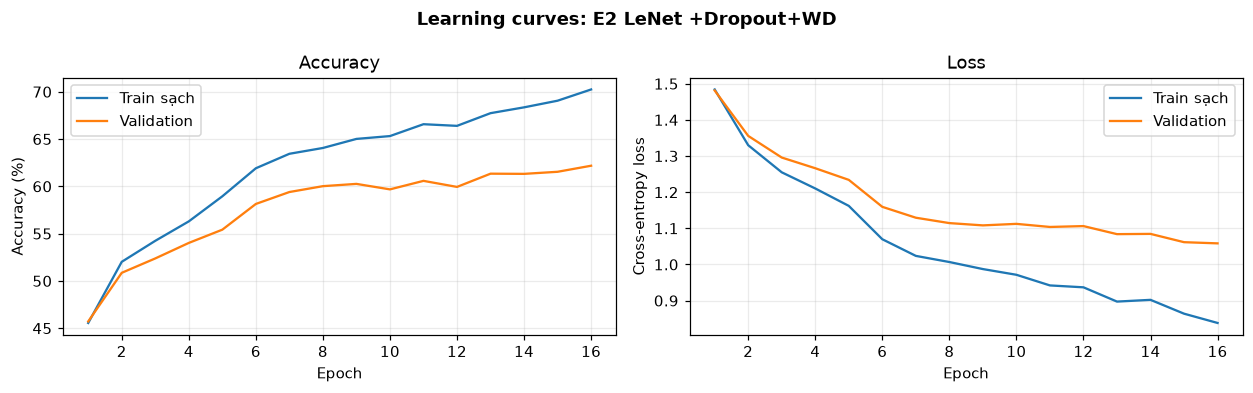


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E2 LeNet +Dropout+WD ---
Sai 1891/5000 mẫu (37.82%); đúng 62.18%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 149 mẫu
  automobile → truck: 92 mẫu
  cat → dog: 85 mẫu
Confidence trung bình của các mẫu sai: 48.69%


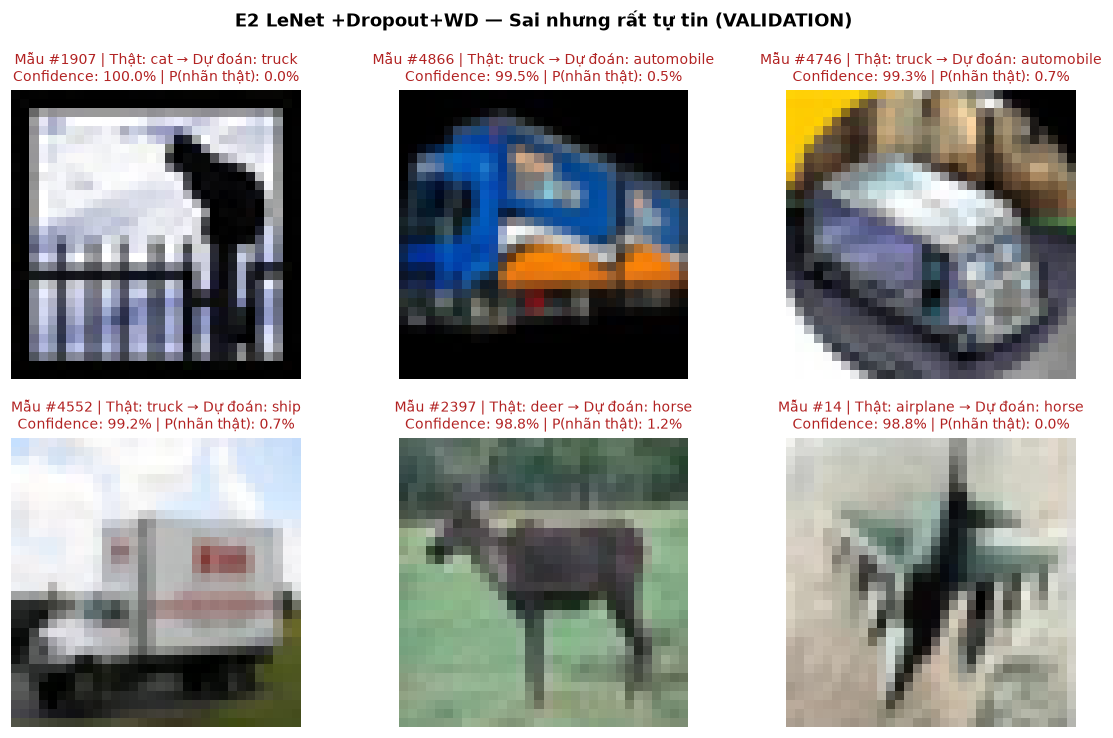

In [14]:
result_E2 = run_experiment(
    "E2 LeNet +Dropout+WD", lambda: LeNet(activation="relu", pool="max", dropout=.35), use_aug=False, wd=1e-3
)
HISTORIES[result_E2["model"]].to_csv(RESULT_DIR / "lich_su_E2.csv", index=False)
VAL_ANALYSES[result_E2["model"]]["details"].to_csv(RESULT_DIR / "validation_E2.csv", index=False)

**Nhận xét E2 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **16**, train accuracy **70.24%**, validation accuracy **62.18%**, validation loss **1.0583**, gap train–validation **+8.06 điểm phần trăm**. So với E1, validation accuracy thay đổi **-0.10 điểm phần trăm**, validation loss từ **1.0692** thành **1.0583**.

Mô hình sai **1891/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 149 ảnh; automobile → truck: 92 ảnh; cat → dog: 85 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

Thêm đồng thời Dropout và weight decay nên không quy chênh lệch cho riêng một kỹ thuật. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Validation loss thấp nhất xuất hiện ở epoch 16, cũng là cuối lịch huấn luyện đang dùng. Kết quả này chỉ phản ánh 16 epoch; chưa xác định được việc huấn luyện lâu hơn sẽ cải thiện hay làm giảm khả năng tổng quát hóa.

### E3. Thêm augmentation


=== E3 LeNet +Augmentation ===
params=62,006 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.8136   | 1.4920     | 45.16%  | 1.4947   | 45.14%  | *
02/16 | 1.5656   | 1.4115     | 49.22%  | 1.4203   | 48.82%  | *
03/16 | 1.4788   | 1.2912     | 53.04%  | 1.3144   | 52.24%  | *
04/16 | 1.4215   | 1.2459     | 55.30%  | 1.2759   | 54.14%  | *
05/16 | 1.3783   | 1.1771     | 57.45%  | 1.2167   | 55.72%  | *
06/16 | 1.3551   | 1.1627     | 58.42%  | 1.2097   | 57.08%  | *
07/16 | 1.3305   | 1.1249     | 59.55%  | 1.1744   | 58.22%  | *
08/16 | 1.3079   | 1.1130     | 60.35%  | 1.1627   | 59.24%  | *
09/16 | 1.3018   | 1.0825     | 61.24%  | 1.1401   | 59.00%  | *
10/16 | 1.2752   | 1.0849     | 61.13%  | 1.1403   | 60.02%  | 
11/16 | 1.2701   | 1.0402     | 62.96%  | 1.1018   | 60.50%  | *
12/16 | 1.2526   | 1.0547  

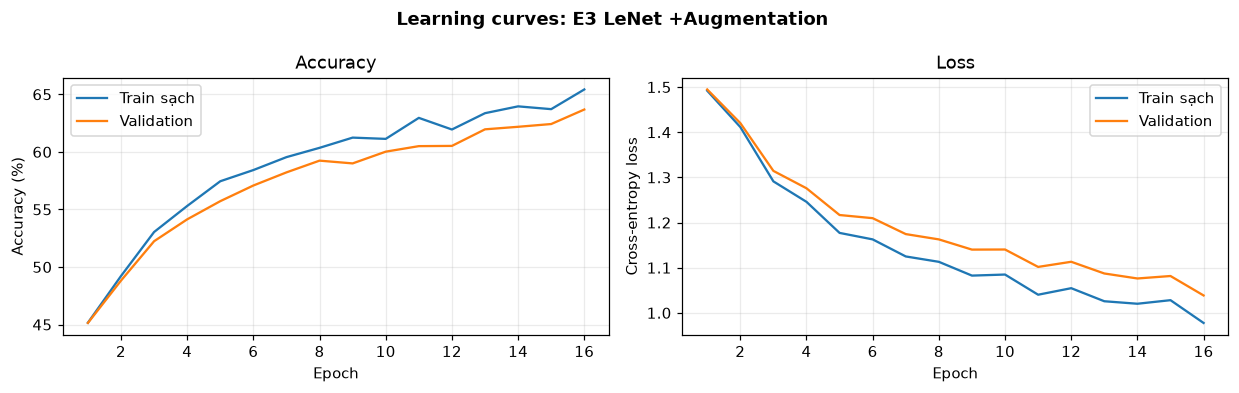


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E3 LeNet +Augmentation ---
Sai 1816/5000 mẫu (36.32%); đúng 63.68%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 106 mẫu
  cat → dog: 101 mẫu
  cat → frog: 66 mẫu
Confidence trung bình của các mẫu sai: 45.63%


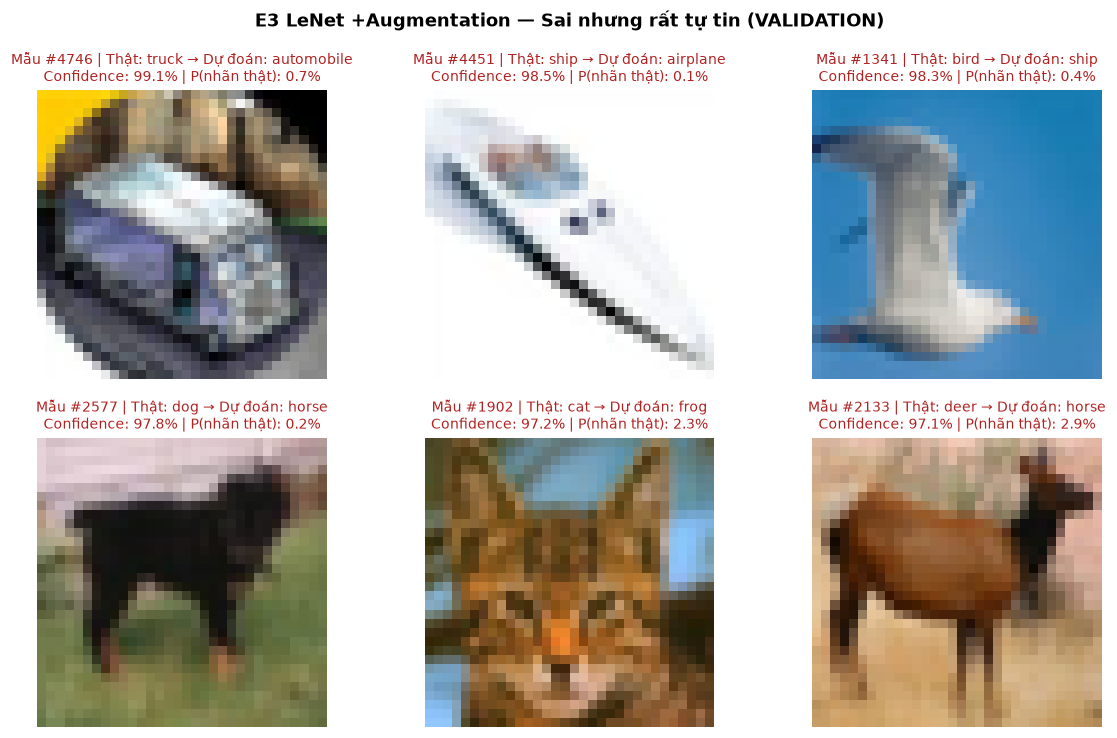

In [15]:
result_E3 = run_experiment(
    "E3 LeNet +Augmentation", lambda: LeNet(activation="relu", pool="max", dropout=.35), use_aug=True, wd=1e-3
)
HISTORIES[result_E3["model"]].to_csv(RESULT_DIR / "lich_su_E3.csv", index=False)
VAL_ANALYSES[result_E3["model"]]["details"].to_csv(RESULT_DIR / "validation_E3.csv", index=False)

**Nhận xét E3 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **16**, train accuracy **65.42%**, validation accuracy **63.68%**, validation loss **1.0386**, gap train–validation **+1.74 điểm phần trăm**. So với E2, validation accuracy thay đổi **+1.50 điểm phần trăm**, validation loss từ **1.0583** thành **1.0386**.

Mô hình sai **1816/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 106 ảnh; cat → dog: 101 ảnh; cat → frog: 66 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

Đây là tác động quan sát được khi thêm đúng hai phép augmentation đã học, trong lần chạy này. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Validation loss thấp nhất xuất hiện ở epoch 16, cũng là cuối lịch huấn luyện đang dùng. Kết quả này chỉ phản ánh 16 epoch; chưa xác định được việc huấn luyện lâu hơn sẽ cải thiện hay làm giảm khả năng tổng quát hóa.

### E4. Thêm BatchNorm


=== E4 LeNet +BatchNorm ===
params=62,050 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7628   | 1.4341     | 47.14%  | 1.4463   | 47.06%  | *
02/16 | 1.5373   | 1.3327     | 51.04%  | 1.3424   | 51.68%  | *
03/16 | 1.4528   | 1.2645     | 54.61%  | 1.2934   | 54.90%  | *
04/16 | 1.4018   | 1.1907     | 57.80%  | 1.2166   | 56.62%  | *
05/16 | 1.3540   | 1.1801     | 57.70%  | 1.2073   | 56.80%  | *
06/16 | 1.3308   | 1.0847     | 61.61%  | 1.1213   | 60.22%  | *
07/16 | 1.3018   | 1.0697     | 62.06%  | 1.1136   | 60.74%  | *
08/16 | 1.2825   | 1.0749     | 61.68%  | 1.1130   | 60.60%  | *
09/16 | 1.2703   | 1.0436     | 62.72%  | 1.0878   | 61.52%  | *
10/16 | 1.2430   | 1.0418     | 63.77%  | 1.0972   | 62.26%  | 
11/16 | 1.2418   | 1.0447     | 63.01%  | 1.0897   | 62.08%  | 
12/16 | 1.2287   | 1.0272     |

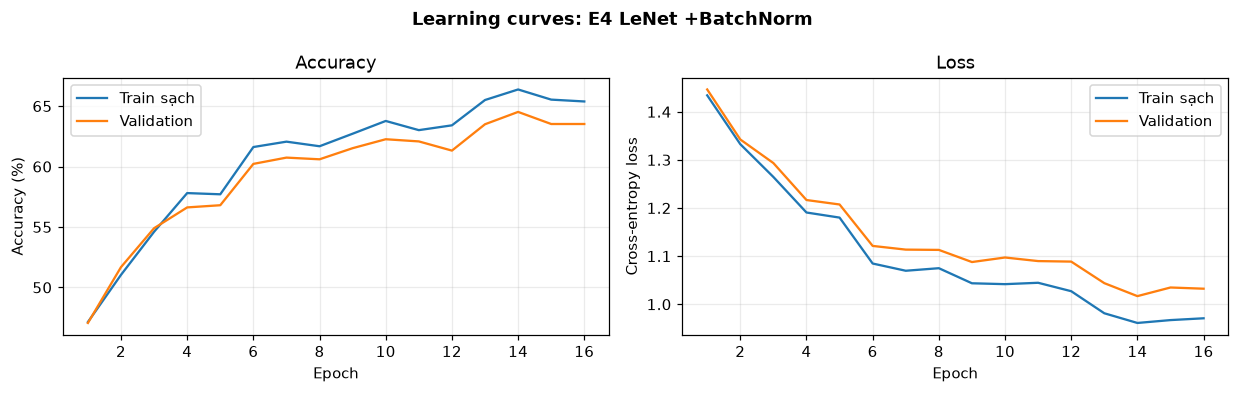


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E4 LeNet +BatchNorm ---
Sai 1774/5000 mẫu (35.48%); đúng 64.52%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 135 mẫu
  cat → dog: 80 mẫu
  automobile → truck: 67 mẫu
Confidence trung bình của các mẫu sai: 44.10%


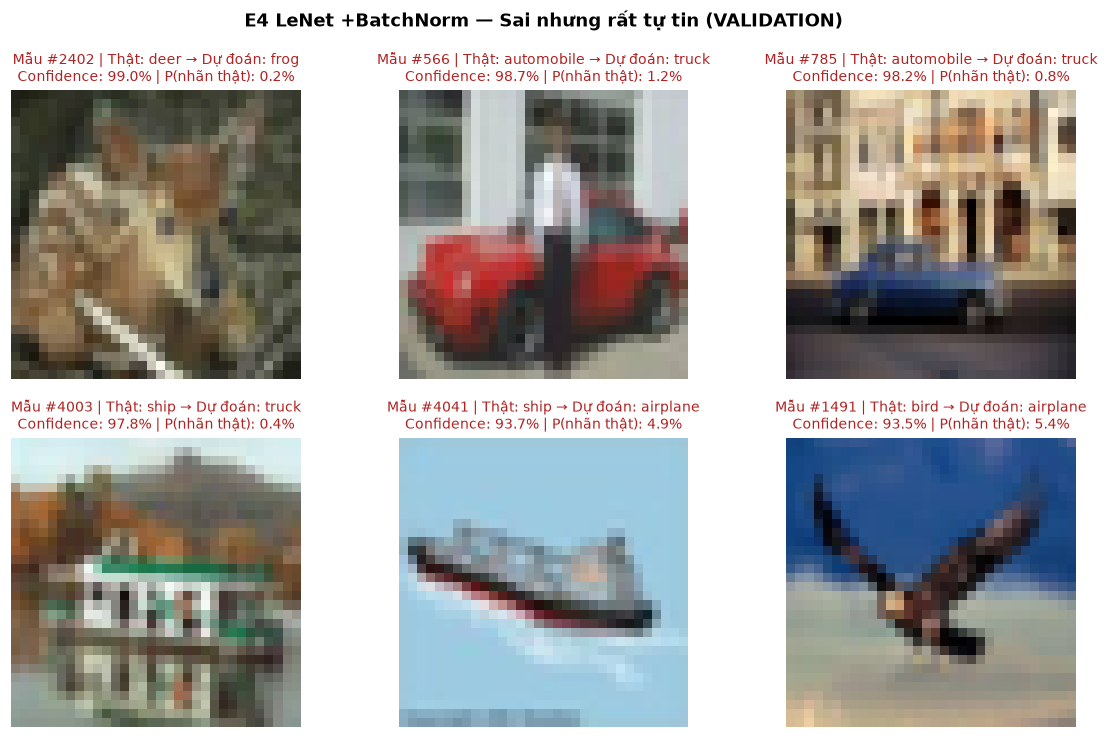

In [16]:
result_E4 = run_experiment(
    "E4 LeNet +BatchNorm", lambda: LeNet(activation="relu", pool="max", batchnorm=True, dropout=.35), use_aug=True, wd=1e-3
)
HISTORIES[result_E4["model"]].to_csv(RESULT_DIR / "lich_su_E4.csv", index=False)
VAL_ANALYSES[result_E4["model"]]["details"].to_csv(RESULT_DIR / "validation_E4.csv", index=False)

**Nhận xét E4 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **14**, train accuracy **66.38%**, validation accuracy **64.52%**, validation loss **1.0169**, gap train–validation **+1.86 điểm phần trăm**. So với E3, validation accuracy thay đổi **+0.84 điểm phần trăm**, validation loss từ **1.0386** thành **1.0169**.

Mô hình sai **1774/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 135 ảnh; cat → dog: 80 ảnh; automobile → truck: 67 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

So với E3, chỉ thêm BatchNorm; kết quả chỉ phản ánh cấu hình và seed đang dùng. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 14 đến epoch 16, train loss từ 0.9612 thành 0.9709, còn validation loss từ 1.0169 thành 1.0324. Epoch cuối có validation loss cao hơn, nên giữ checkpoint đã chọn theo quy tắc chung.

### M1. VGG-tiny


=== M1 VGG-tiny ===
params=77,114 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.5368   | 1.2246     | 56.09%  | 1.2462   | 55.16%  | *
02/16 | 1.1904   | 1.0267     | 62.15%  | 1.0581   | 61.30%  | *
03/16 | 1.0607   | 0.8814     | 68.13%  | 0.8924   | 67.54%  | *
04/16 | 0.9717   | 0.8172     | 70.42%  | 0.8427   | 69.70%  | *
05/16 | 0.9160   | 0.8430     | 69.83%  | 0.8703   | 69.20%  | 
06/16 | 0.8730   | 0.7278     | 73.82%  | 0.7552   | 72.80%  | *
07/16 | 0.8259   | 0.6511     | 76.97%  | 0.6915   | 75.36%  | *
08/16 | 0.7952   | 0.6894     | 74.95%  | 0.7376   | 73.70%  | 
09/16 | 0.7684   | 0.6533     | 76.88%  | 0.6965   | 75.54%  | 
10/16 | 0.7416   | 0.6053     | 78.62%  | 0.6640   | 76.70%  | *
11/16 | 0.7142   | 0.5939     | 78.92%  | 0.6515   | 77.08%  | *
12/16 | 0.7034   | 0.5851     | 79.49%  

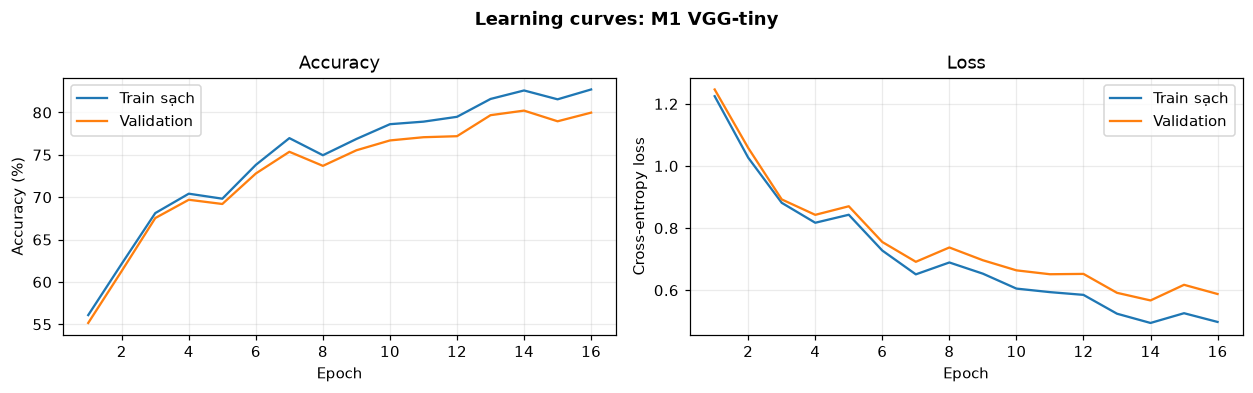


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M1 VGG-tiny ---
Sai 989/5000 mẫu (19.78%); đúng 80.22%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 110 mẫu
  cat → dog: 53 mẫu
  frog → cat: 40 mẫu
Confidence trung bình của các mẫu sai: 59.52%


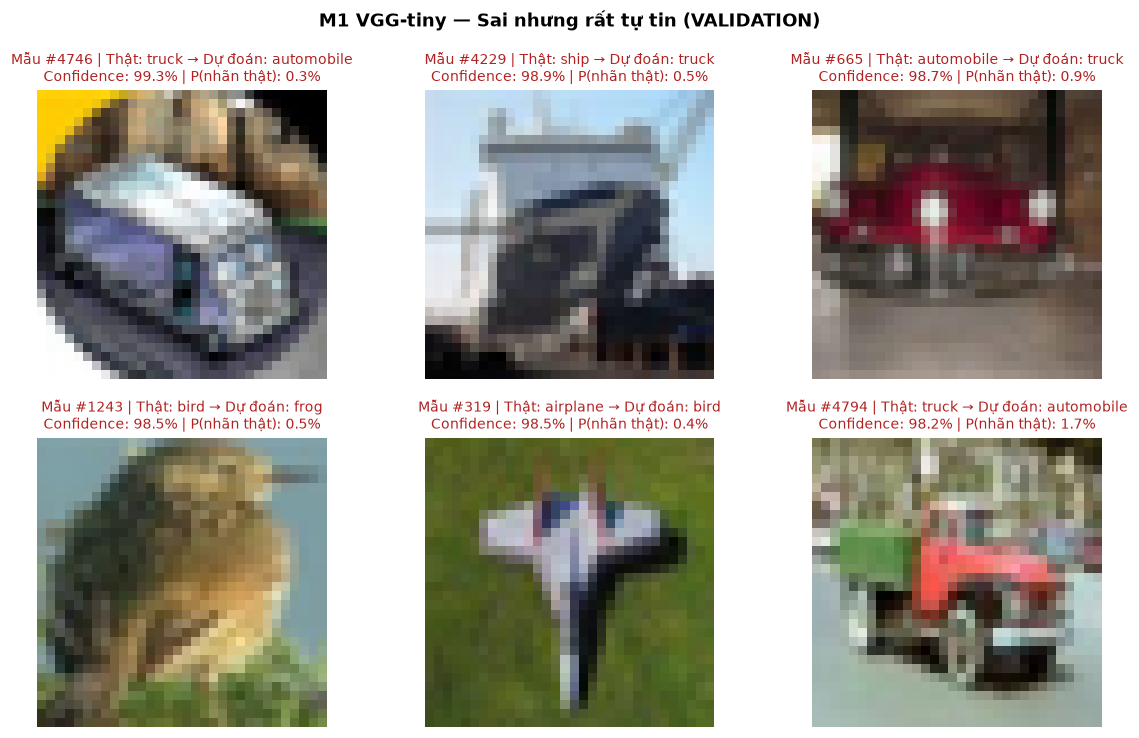

In [17]:
result_M1 = run_experiment(
    "M1 VGG-tiny", VGGTiny, use_aug=True, wd=1e-3
)
HISTORIES[result_M1["model"]].to_csv(RESULT_DIR / "lich_su_M1.csv", index=False)
VAL_ANALYSES[result_M1["model"]]["details"].to_csv(RESULT_DIR / "validation_M1.csv", index=False)

**Nhận xét M1 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **14**, train accuracy **82.60%**, validation accuracy **80.22%**, validation loss **0.5671**, gap train–validation **+2.38 điểm phần trăm**.

Mô hình sai **989/5.000 ảnh validation**. Các cặp nhầm nhiều: dog → cat: 110 ảnh; cat → dog: 53 ảnh; frog → cat: 40 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

VGG-tiny dùng các convolution 3×3 lặp lại và head có global average pooling như bài mẫu. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 14 đến epoch 16, train loss từ 0.4946 thành 0.4979, còn validation loss từ 0.5671 thành 0.5879. Epoch cuối có validation loss cao hơn, nên giữ checkpoint đã chọn theo quy tắc chung.

### M2. Inception-tiny


=== M2 Inception-tiny ===
params=27,850 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.6307   | 1.3138     | 51.37%  | 1.3329   | 50.96%  | *
02/16 | 1.3138   | 1.2114     | 55.57%  | 1.2407   | 54.40%  | *
03/16 | 1.1936   | 0.9867     | 64.48%  | 1.0172   | 63.46%  | *
04/16 | 1.1318   | 1.0207     | 62.96%  | 1.0460   | 61.74%  | 
05/16 | 1.0812   | 0.9105     | 67.12%  | 0.9380   | 66.62%  | *
06/16 | 1.0417   | 0.8797     | 68.64%  | 0.9176   | 66.64%  | *
07/16 | 1.0105   | 0.8511     | 69.82%  | 0.8836   | 68.42%  | *
08/16 | 0.9805   | 0.8084     | 71.14%  | 0.8424   | 70.06%  | *
09/16 | 0.9577   | 0.7955     | 71.65%  | 0.8346   | 69.96%  | *
10/16 | 0.9428   | 0.7636     | 72.80%  | 0.8061   | 71.46%  | *
11/16 | 0.9200   | 0.7350     | 73.90%  | 0.7755   | 72.92%  | *
12/16 | 0.9050   | 0.7407     | 

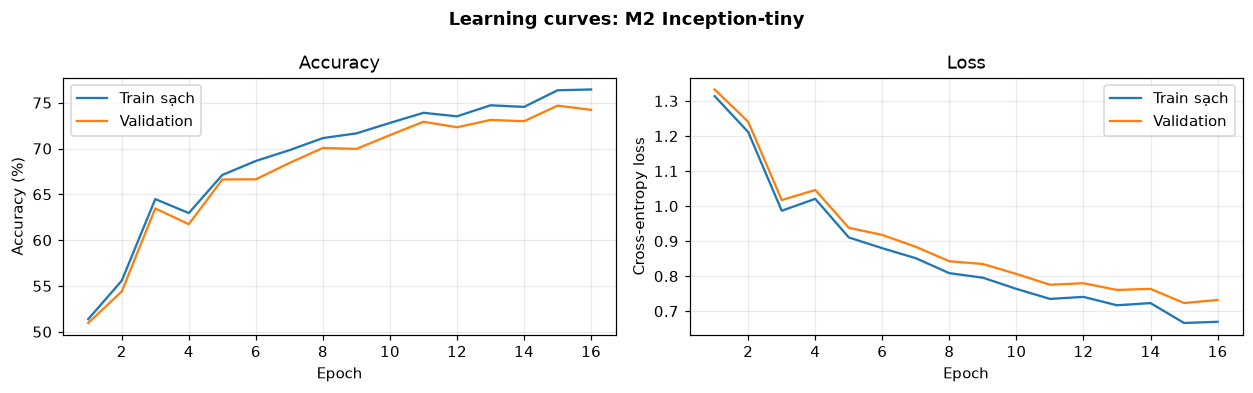


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M2 Inception-tiny ---
Sai 1266/5000 mẫu (25.32%); đúng 74.68%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  cat → dog: 101 mẫu
  dog → cat: 74 mẫu
  bird → deer: 48 mẫu
Confidence trung bình của các mẫu sai: 55.71%


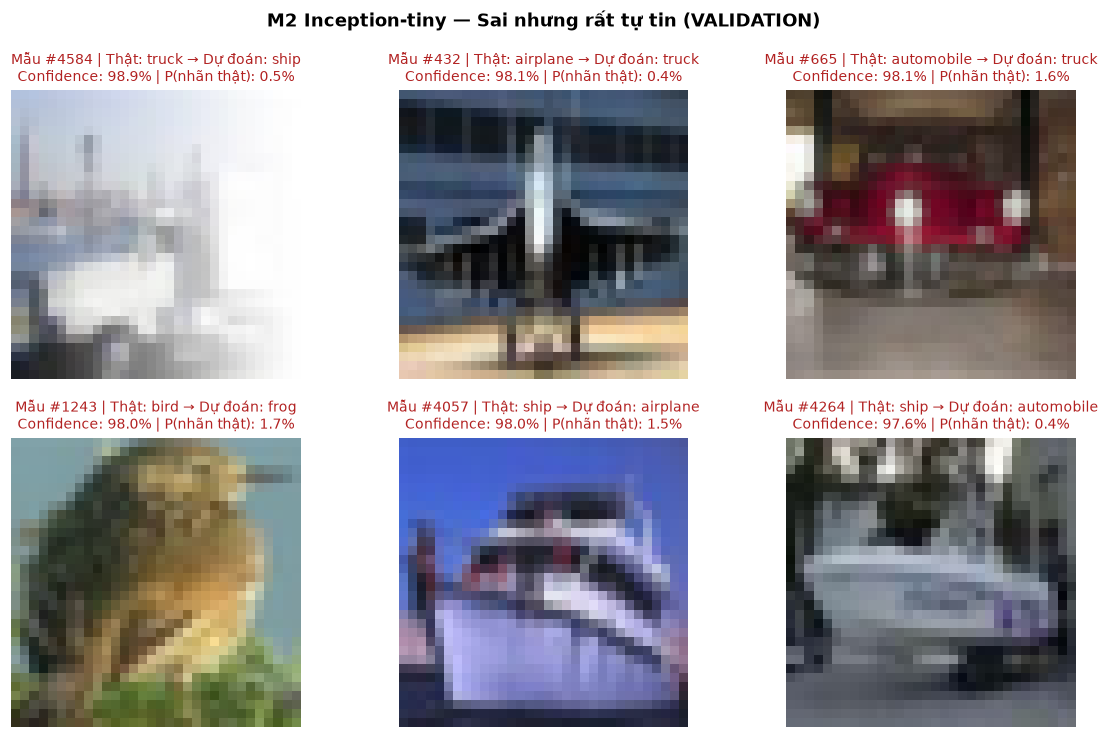

In [18]:
result_M2 = run_experiment(
    "M2 Inception-tiny", InceptionTiny, use_aug=True, wd=1e-3
)
HISTORIES[result_M2["model"]].to_csv(RESULT_DIR / "lich_su_M2.csv", index=False)
VAL_ANALYSES[result_M2["model"]]["details"].to_csv(RESULT_DIR / "validation_M2.csv", index=False)

**Nhận xét M2 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **15**, train accuracy **76.36%**, validation accuracy **74.68%**, validation loss **0.7232**, gap train–validation **+1.68 điểm phần trăm**.

Mô hình sai **1266/5.000 ảnh validation**. Các cặp nhầm nhiều: cat → dog: 101 ảnh; dog → cat: 74 ảnh; bird → deer: 48 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

Inception-tiny xử lý nhiều nhánh rồi nối theo chiều kênh; độ phức tạp hơn không bảo đảm điểm cao hơn. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 15 đến epoch 16, train loss từ 0.6663 thành 0.6696, còn validation loss từ 0.7232 thành 0.7319. Epoch cuối có validation loss cao hơn, nên giữ checkpoint đã chọn theo quy tắc chung.

### M3. ResNet-tiny


=== M3 ResNet-tiny ===
params=170,586 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.4527   | 1.1315     | 59.18%  | 1.1610   | 58.82%  | *
02/16 | 1.0783   | 1.0012     | 63.94%  | 1.0397   | 63.56%  | *
03/16 | 0.9357   | 0.9161     | 67.93%  | 0.9500   | 67.44%  | *
04/16 | 0.8408   | 0.7784     | 72.36%  | 0.8238   | 71.30%  | *
05/16 | 0.7676   | 0.7473     | 73.74%  | 0.7918   | 72.20%  | *
06/16 | 0.7135   | 0.6415     | 77.61%  | 0.6879   | 76.38%  | *
07/16 | 0.6703   | 0.5965     | 79.06%  | 0.6543   | 76.96%  | *
08/16 | 0.6329   | 0.5977     | 78.54%  | 0.6679   | 76.88%  | 
09/16 | 0.6005   | 0.4986     | 82.77%  | 0.5781   | 79.54%  | *
10/16 | 0.5696   | 0.4463     | 84.56%  | 0.5314   | 82.00%  | *
11/16 | 0.5531   | 0.4850     | 83.33%  | 0.5753   | 80.54%  | 
12/16 | 0.5298   | 0.4262     | 84.

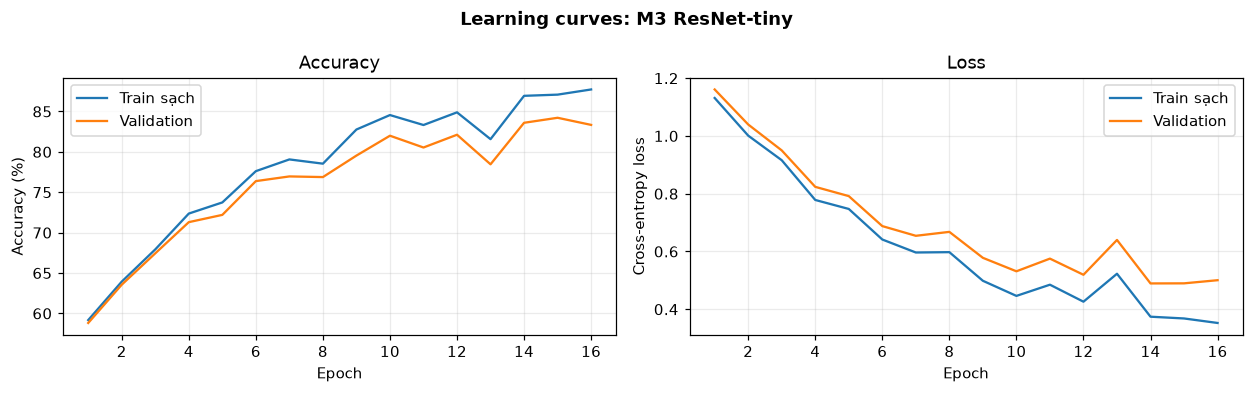


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M3 ResNet-tiny ---
Sai 820/5000 mẫu (16.40%); đúng 83.60%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  cat → dog: 69 mẫu
  dog → cat: 52 mẫu
  cat → bird: 38 mẫu
Confidence trung bình của các mẫu sai: 61.97%


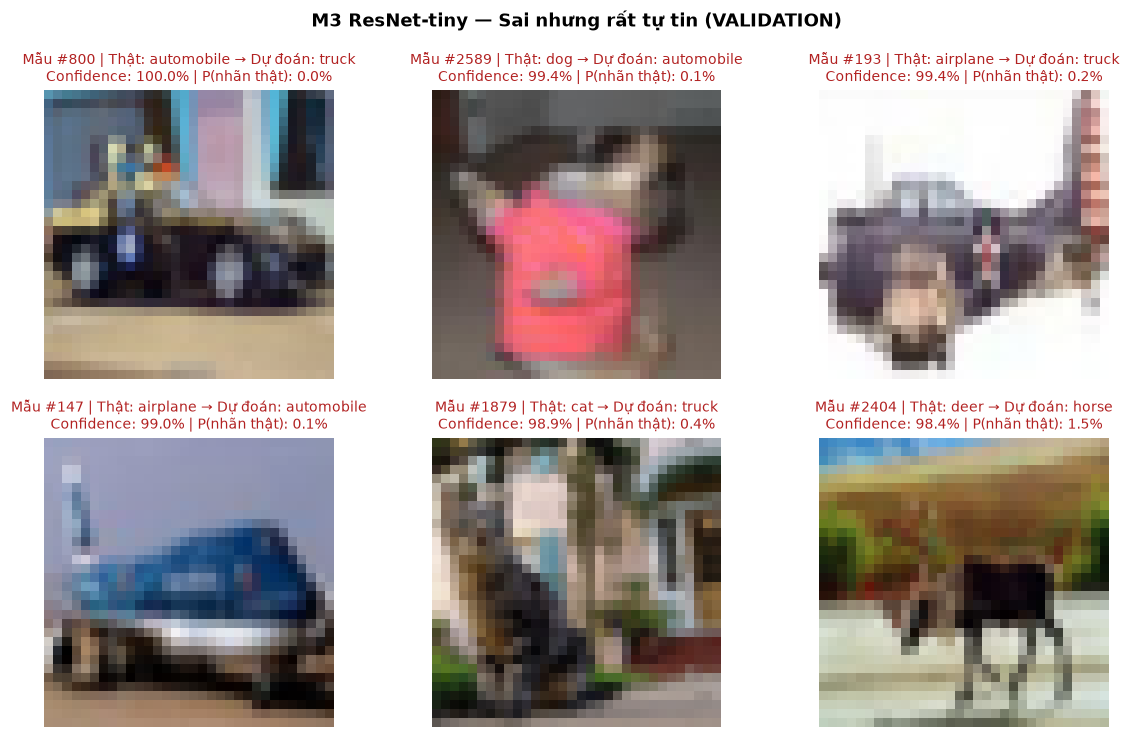

In [19]:
result_M3 = run_experiment(
    "M3 ResNet-tiny", ResNetTiny, use_aug=True, wd=1e-3
)
HISTORIES[result_M3["model"]].to_csv(RESULT_DIR / "lich_su_M3.csv", index=False)
VAL_ANALYSES[result_M3["model"]]["details"].to_csv(RESULT_DIR / "validation_M3.csv", index=False)

**Nhận xét M3 — kết quả chạy CIFAR-10:** Checkpoint ở epoch **14**, train accuracy **86.94%**, validation accuracy **83.60%**, validation loss **0.4894**, gap train–validation **+3.34 điểm phần trăm**.

Mô hình sai **820/5.000 ảnh validation**. Các cặp nhầm nhiều: cat → dog: 69 ảnh; dog → cat: 52 ảnh; cat → bird: 38 ảnh. Các ảnh sai phía trên đã được hoàn nguyên chuẩn hóa; confidence là xác suất softmax của lớp dự đoán.

ResNet-tiny dùng F(x) + S(x); skip connection phải khớp kích thước với nhánh residual. Cần đọc đồng thời loss, accuracy và đường học; một seed chưa đủ để kết luận tổng quát.

**Đọc đường học:** Từ checkpoint epoch 14 đến epoch 16, train loss từ 0.3742 thành 0.3526, còn validation loss từ 0.4894 thành 0.5006. Train loss tiếp tục giảm trong khi validation loss tăng là dấu hiệu học sát tập train hơn nhưng khả năng tổng quát hóa giảm ở giai đoạn cuối. Vì vậy dùng checkpoint đã chọn thay cho trọng số epoch cuối.

## BT6. So sánh trên validation và chọn mô hình

Xếp hạng theo **validation loss tăng dần**, dùng validation accuracy giảm dần khi bằng loss.
Quy tắc đã đặt trước khi đánh giá test. Accuracy và cross-entropy có thể chọn mô hình
khác nhau vì cross-entropy còn phản ánh xác suất gán cho nhãn thật.

In [27]:
if len(RESULTS) != 8:
    raise RuntimeError(f"Cần đủ 8 thí nghiệm; hiện có {len(RESULTS)}")
summary_df = pd.DataFrame(RESULTS).sort_values(["val_loss", "val_acc"],
                                             ascending=[True, False]).reset_index(drop=True)
full_rows = []
for result in RESULTS:
    h = HISTORIES[result["model"]]
    checkpoint = h.loc[h.epoch == result["best_epoch"]].iloc[0]
    full_rows.append({**result, "train_loss": float(checkpoint.train_loss),
                      "opt_loss": float(checkpoint.opt_loss), "opt_acc": float(checkpoint.opt_acc)})
full_summary = pd.DataFrame(full_rows).sort_values(["val_loss", "val_acc"], ascending=[True, False]).reset_index(drop=True)
shown = full_summary[["model", "parameters", "best_epoch", "train_loss", "train_acc", "val_loss", "val_acc", "gap", "val_errors", "seconds"]].copy()
for col in ["train_acc", "val_acc", "gap"]:
    shown[col] *= 100
shown = shown.rename(columns={"model": "Cấu hình", "parameters": "Tham số", "best_epoch": "Epoch chọn",
    "train_loss": "Train loss", "train_acc": "Train acc (%)", "val_loss": "Val loss",
    "val_acc": "Val acc (%)", "gap": "Gap (đpt)", "val_errors": "Sai/5000 val", "seconds": "Huấn luyện (s)"})
print("TỔNG HỢP TẠI CHECKPOINT CÓ VALIDATION LOSS NHỎ NHẤT CỦA MỖI CẤU HÌNH:")
display(shown.style.format({"Train loss": "{:.4f}", "Val loss": "{:.4f}", "Train acc (%)": "{:.2f}",
                           "Val acc (%)": "{:.2f}", "Gap (đpt)": "{:+.2f}", "Huấn luyện (s)": "{:.2f}"}))
summary_df.to_csv(RESULT_DIR / "tong_hop_validation.csv", index=False)
full_summary.to_csv(RESULT_DIR / "tong_hop_day_du.csv", index=False)

TỔNG HỢP TẠI CHECKPOINT CÓ VALIDATION LOSS NHỎ NHẤT CỦA MỖI CẤU HÌNH:


,Cấu hình,Tham số,Epoch chọn,Train loss,Train acc (%),Val loss,Val acc (%),Gap (đpt),Sai/5000 val,Huấn luyện (s)
0,M3 ResNet-tiny,170586,14,0.3742,86.94,0.4894,83.60,+3.34,820,589.18
1,M1 VGG-tiny,77114,14,0.4946,82.60,0.5671,80.22,+2.38,989,606.71
2,M2 Inception-tiny,27850,15,0.6663,76.36,0.7232,74.68,+1.68,1266,594.54
3,E4 LeNet +BatchNorm,62050,14,0.9612,66.38,1.0169,64.52,+1.86,1774,472.36
4,E3 LeNet +Augmentation,62006,16,0.9776,65.42,1.0386,63.68,+1.74,1816,485.88
5,E2 LeNet +Dropout+WD,62006,16,0.8381,70.24,1.0583,62.18,+8.06,1891,68.52
6,E1 LeNet ReLU+Max,62006,6,0.9292,67.39,1.0692,62.28,+5.11,1886,72.74
7,E0 LeNet Tanh+Avg,62006,11,0.8662,69.57,1.2389,57.22,+12.35,2139,75.41


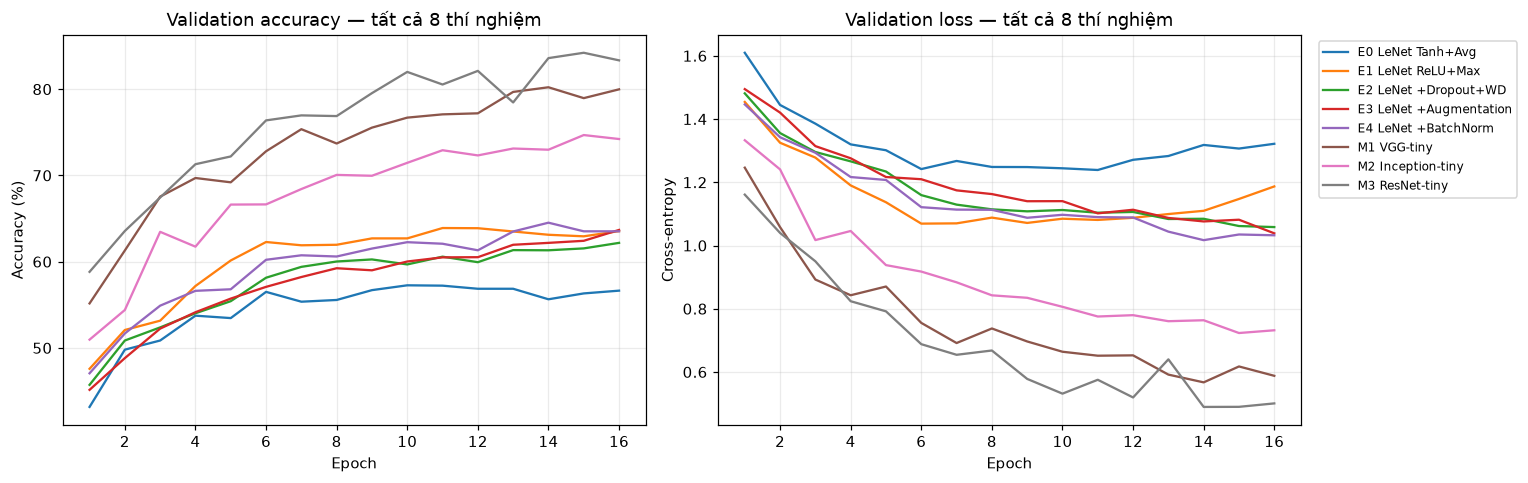


SO SÁNH CÁC BƯỚC LE-NET (đơn vị: điểm phần trăm trên validation):
E0 → E1 (ReLU + MaxPool): +5.06 pp
E1 → E2 (Dropout + weight decay): -0.10 pp
E2 → E3 (thêm augmentation): +1.50 pp
E3 → E4 (thêm BatchNorm): +0.84 pp


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in HISTORIES.items():
    axes[0].plot(h.epoch, h.val_acc * 100, label=name)
    axes[1].plot(h.epoch, h.val_loss, label=name)
axes[0].set(title="Validation accuracy — tất cả 8 thí nghiệm", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].set(title="Validation loss — tất cả 8 thí nghiệm", xlabel="Epoch", ylabel="Cross-entropy")
for ax in axes:
    ax.grid(alpha=.25)
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("\nSO SÁNH CÁC BƯỚC LE-NET (đơn vị: điểm phần trăm trên validation):")
ordered = pd.DataFrame(RESULTS).set_index("model")
comparisons = [
    ("E0 LeNet Tanh+Avg", "E1 LeNet ReLU+Max", "ReLU + MaxPool"),
    ("E1 LeNet ReLU+Max", "E2 LeNet +Dropout+WD", "Dropout + weight decay"),
    ("E2 LeNet +Dropout+WD", "E3 LeNet +Augmentation", "thêm augmentation"),
    ("E3 LeNet +Augmentation", "E4 LeNet +BatchNorm", "thêm BatchNorm"),
]
for a, b, label in comparisons:
    delta = 100 * (ordered.loc[b, "val_acc"] - ordered.loc[a, "val_acc"])
    print(f"{a[:2]} → {b[:2]} ({label}): {delta:+.2f} pp")

### Bảng thay đổi qua từng bước LeNet

Δ = cấu hình sau − cấu hình trước, tính từ số liệu chưa làm tròn; accuracy/gap dùng điểm phần trăm (đpt). Thời gian trong bảng tổng hợp là thời gian huấn luyện 16 epoch trên máy đã chạy, không phải benchmark phần cứng chuẩn hóa.

In [28]:
comparison_rows = []
by_model = pd.DataFrame(RESULTS).set_index("model")
pairs = [("E0 LeNet Tanh+Avg", "E1 LeNet ReLU+Max", "Activation + pooling"),
         ("E1 LeNet ReLU+Max", "E2 LeNet +Dropout+WD", "Dropout + weight decay"),
         ("E2 LeNet +Dropout+WD", "E3 LeNet +Augmentation", "Augmentation"),
         ("E3 LeNet +Augmentation", "E4 LeNet +BatchNorm", "BatchNorm")]
for before, after, change in pairs:
    a, b = by_model.loc[before], by_model.loc[after]
    comparison_rows.append({"So sánh": f"{before[:2]} → {after[:2]}", "Thay đổi": change,
        "Δ Val loss": b.val_loss - a.val_loss, "Δ Val acc (đpt)": 100 * (b.val_acc - a.val_acc),
        "Δ Gap (đpt)": 100 * (b.gap - a.gap), "Δ Số lỗi val": int(b.val_errors - a.val_errors)})
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.style.format({"Δ Val loss": "{:+.4f}", "Δ Val acc (đpt)": "{:+.2f}", "Δ Gap (đpt)": "{:+.2f}"}))
comparison_table.to_csv(RESULT_DIR / "so_sanh_cac_buoc_LeNet.csv", index=False)

,So sánh,Thay đổi,Δ Val loss,Δ Val acc (đpt),Δ Gap (đpt),Δ Số lỗi val
0,E0 → E1,Activation + pooling,-0.1697,+5.06,-7.25,-253
1,E1 → E2,Dropout + weight decay,-0.0109,-0.10,+2.95,5
2,E2 → E3,Augmentation,-0.0198,+1.50,-6.32,-75
3,E3 → E4,BatchNorm,-0.0216,+0.84,+0.12,-42


### Bảng tỷ lệ lỗi validation theo lớp của cả 8 cấu hình

In [29]:
class_error_rows = []
for model_name, analysis in VAL_ANALYSES.items():
    for label, part in analysis["details"].groupby("true_label"):
        class_error_rows.append({"tag": model_name[:2], "model": model_name,
            "class_name": CLASS_NAMES[label], "n_samples": len(part),
            "n_correct": int(part.correct.sum()), "n_errors": int((~part.correct).sum()),
            "error_rate_pct": 100 * (~part.correct).mean()})
class_errors_all = pd.DataFrame(class_error_rows)
error_rate_table = class_errors_all.pivot(index="class_name", columns="tag", values="error_rate_pct").reindex(CLASS_NAMES)
print("TỶ LỆ SAI VALIDATION THEO LỚP (%): MỖI Ô CÓ MẪU SỐ 500 ẢNH")
display(error_rate_table.style.format("{:.2f}%"))
class_errors_all.to_csv(RESULT_DIR / "loi_theo_lop_8_thi_nghiem.csv", index=False)
error_rate_table.to_csv(RESULT_DIR / "ty_le_sai_validation_8_cau_hinh.csv")

TỶ LỆ SAI VALIDATION THEO LỚP (%): MỖI Ô CÓ MẪU SỐ 500 ẢNH


tag,E0,E1,E2,E3,E4,M1,M2,M3
class_name,,,,,,,,
airplane,44.20%,36.20%,42.40%,30.60%,40.80%,19.40%,23.20%,13.40%
automobile,27.40%,20.40%,27.00%,22.20%,23.40%,5.80%,8.00%,4.80%
bird,51.40%,50.40%,53.80%,48.80%,44.60%,29.80%,33.60%,16.20%
cat,52.80%,59.60%,51.60%,60.80%,53.20%,25.20%,53.40%,39.60%
deer,45.60%,43.80%,46.00%,44.00%,44.20%,18.20%,24.40%,22.40%
dog,62.20%,55.00%,59.20%,50.20%,54.80%,37.20%,36.80%,25.60%
frog,41.00%,28.20%,28.60%,23.60%,27.60%,21.40%,23.20%,11.80%
horse,34.40%,32.60%,28.20%,33.20%,32.00%,18.40%,17.20%,15.00%
ship,29.40%,20.00%,20.20%,19.60%,15.80%,8.20%,12.60%,5.80%


**Kết quả lựa chọn:** **M3 ResNet-tiny** có validation loss nhỏ nhất (**0.4894**), validation accuracy **83.60%**, tại epoch **14**. Theo quy tắc đã đặt trước, đây là mô hình được đưa sang đánh giá test. Trong các checkpoint đã chọn theo validation loss, mô hình có validation accuracy lớn nhất là **M3 ResNet-tiny** (**83.60%**).

Các chênh lệch E0→E4 được in ở cell trên. Kết quả chỉ áp dụng cho phép chia, seed và 16 epoch này; không khẳng định một kiến trúc luôn tốt hơn các kiến trúc còn lại.

**Cách đọc bảng:** Accuracy được báo cáo tại checkpoint có validation loss thấp nhất của mỗi thí nghiệm, không phải accuracy cao nhất trong tất cả epoch. Cross-entropy còn phản ánh xác suất gán cho nhãn thật, nên epoch có accuracy cao hơn vẫn có thể có loss cao hơn.

## BT7. Phân tích lỗi validation của mô hình đã chọn

Xem tỷ lệ lỗi theo lớp, ma trận nhầm lẫn (hàng = nhãn thật, cột = nhãn dự đoán),
các mẫu sai có confidence cao và thấp. Confidence là xác suất softmax của lớp được
dự đoán, chưa bảo đảm là xác suất mô hình đúng. Ảnh sai chỉ giúp đặt giả thuyết;
không đủ để khẳng định nguyên nhân.

MÔ HÌNH ĐƯỢC CHỌN BẰNG VALIDATION LOSS: M3 ResNet-tiny
Tổng mẫu validation: 5000 | Dự đoán sai: 820 | Tỷ lệ sai: 16.40%

BẢNG LỖI THEO LỚP — VALIDATION (không có test):


,class_name,n_samples,n_errors,error_rate_pct
0,cat,500,198,39.60%
1,dog,500,128,25.60%
2,deer,500,112,22.40%
3,bird,500,81,16.20%
4,horse,500,75,15.00%
5,airplane,500,67,13.40%
6,frog,500,59,11.80%
7,truck,500,47,9.40%
8,ship,500,29,5.80%
9,automobile,500,24,4.80%


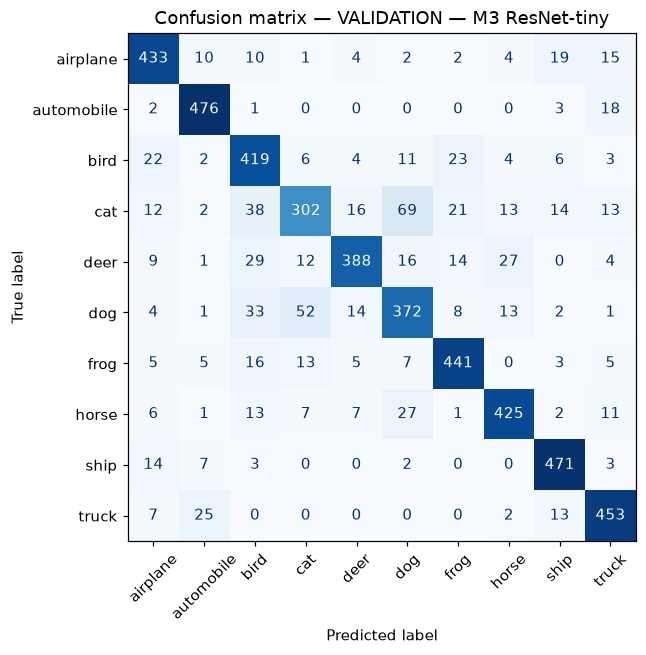

In [22]:
# Chỉ chọn mô hình đã đứng đầu ở bảng validation; không truy cập test_loader.
best_name = summary_df.loc[0, "model"]
best_val_analysis = VAL_ANALYSES[best_name]
val_details = best_val_analysis["details"]
val_images = best_val_analysis["images"]

print("MÔ HÌNH ĐƯỢC CHỌN BẰNG VALIDATION LOSS:", best_name)
print(f"Tổng mẫu validation: {len(val_details)} | "
      f"Dự đoán sai: {best_val_analysis['n_errors']} | "
      f"Tỷ lệ sai: {best_val_analysis['n_errors'] / len(val_details):.2%}")

# Bảng lỗi theo LỚP THẬT (quan trọng khi các lớp không cân bằng).
per_class = (val_details.groupby("true_label", as_index=False)
             .agg(n_samples=("correct", "size"),
                  n_correct=("correct", "sum")))
per_class["n_errors"] = per_class["n_samples"] - per_class["n_correct"]
per_class["error_rate_pct"] = (
    100 * per_class["n_errors"] / per_class["n_samples"])
per_class["class_name"] = per_class["true_label"].map(
    lambda idx: CLASS_NAMES[idx])
per_class = per_class[["class_name", "n_samples", "n_errors", "error_rate_pct"]]
per_class = per_class.sort_values(
    ["error_rate_pct", "n_errors"], ascending=False).reset_index(drop=True)
print("\nBẢNG LỖI THEO LỚP — VALIDATION (không có test):")
display(per_class.style.format({"error_rate_pct": "{:.2f}%"}))

cm_val = confusion_matrix(
    val_details["true_label"], val_details["pred_label"],
    labels=list(range(len(CLASS_NAMES))))
fig, ax = plt.subplots(figsize=(7.4, 6.1))
ConfusionMatrixDisplay(cm_val, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title(f"Confusion matrix — VALIDATION — {best_name}")
plt.tight_layout()
plt.show()

per_class.to_csv(RESULT_DIR / "loi_theo_lop_validation.csv", index=False)

NHÓM A — Các mẫu SAI nhưng confidence CAO:


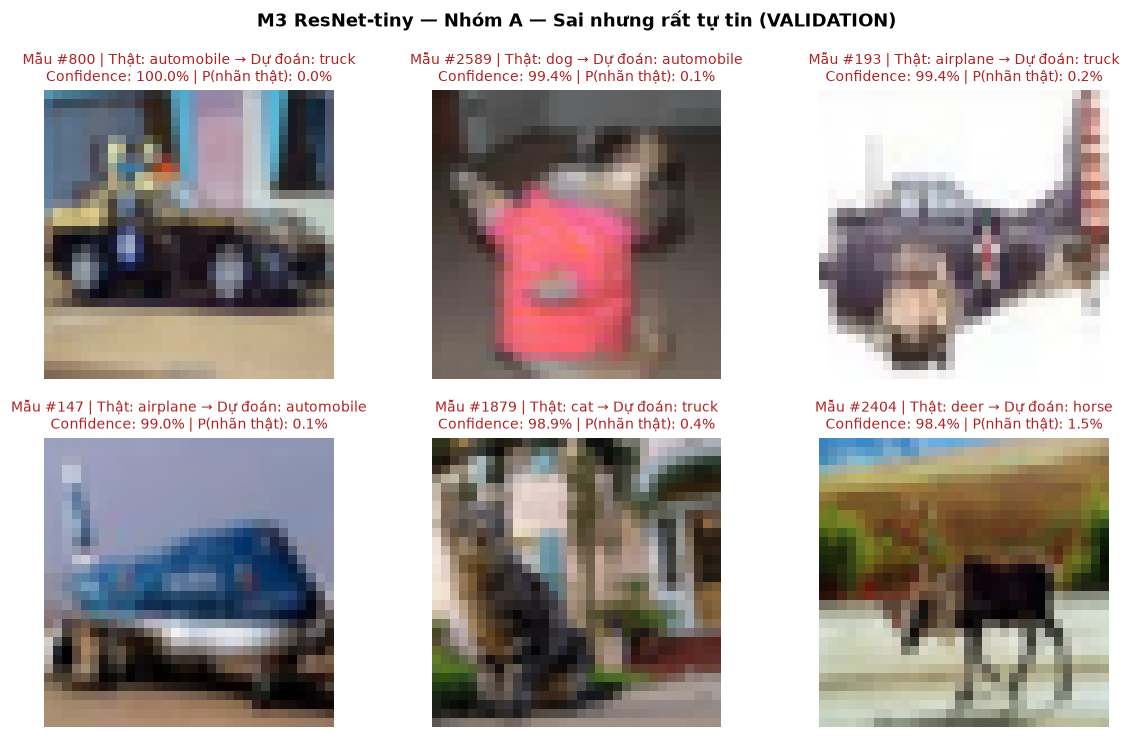

NHÓM B — Các mẫu SAI có confidence THẤP:


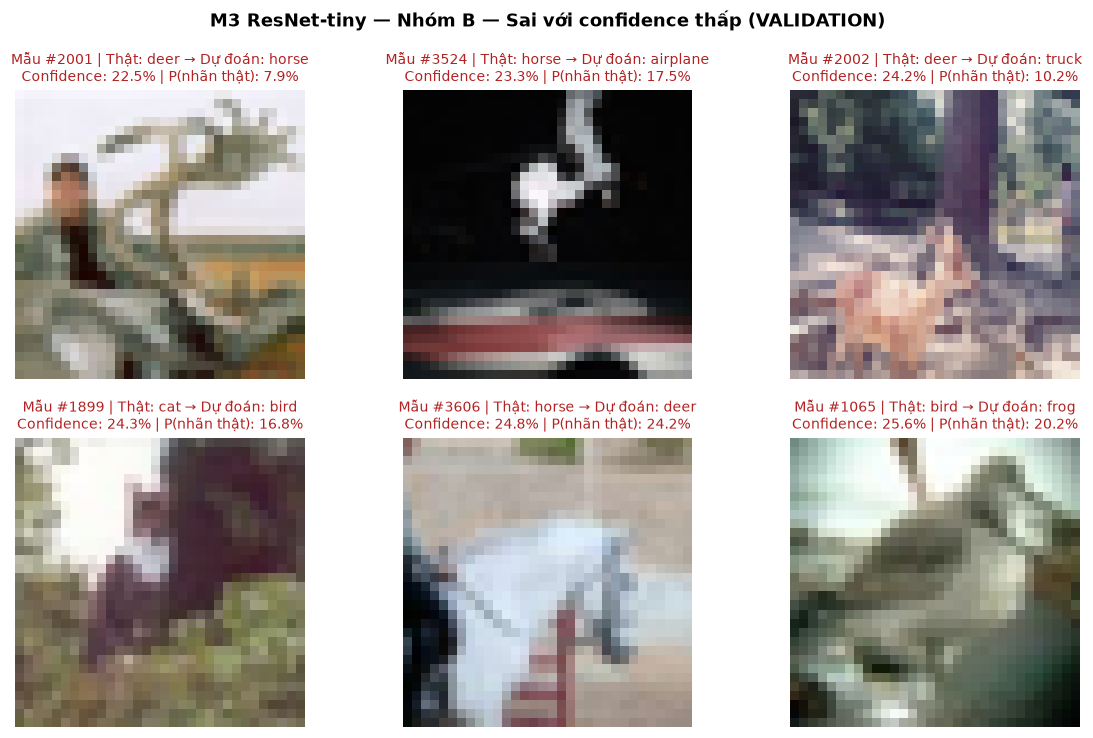

In [23]:
print("NHÓM A — Các mẫu SAI nhưng confidence CAO:")
plot_misclassified_images(
    val_details, val_images, CLASS_NAMES, mean=mu, std=sigma,
    max_examples=6, hardest_first=True, title=f"{best_name} — Nhóm A")

print("NHÓM B — Các mẫu SAI có confidence THẤP:")
plot_misclassified_images(
    val_details, val_images, CLASS_NAMES, mean=mu, std=sigma,
    max_examples=6, hardest_first=False, title=f"{best_name} — Nhóm B")

### Bảng chi tiết các mẫu sai đã minh họa

Confidence là xác suất softmax của nhãn dự đoán; P(nhãn thật) là xác suất gán cho lớp đúng. ID ảnh đối chiếu trực tiếp với `trainLabels.csv`; vị trí validation tính từ 0.

In [30]:
confidence_tables = []
wrong_details = val_details.loc[~val_details.correct]
for group, ascending in [("Sai, confidence cao", False), ("Sai, confidence thấp", True)]:
    part = wrong_details.sort_values("confidence", ascending=ascending).head(6).copy()
    part["Nhóm"] = group
    part["ID ảnh"] = [int(labels_df.iloc[iv[int(i)]]["id"]) for i in part.sample_index]
    part["Thật"] = part.true_label.map(lambda i: CLASS_NAMES[i])
    part["Dự đoán"] = part.pred_label.map(lambda i: CLASS_NAMES[i])
    part["Confidence (%)"] = 100 * part.confidence
    part["P(nhãn thật) (%)"] = 100 * part.p_true
    confidence_tables.append(part[["Nhóm", "sample_index", "ID ảnh", "Thật", "Dự đoán", "Confidence (%)", "P(nhãn thật) (%)"]])
confidence_table = pd.concat(confidence_tables, ignore_index=True).rename(columns={"sample_index": "Vị trí validation"})
display(confidence_table.style.format({"Confidence (%)": "{:.2f}", "P(nhãn thật) (%)": "{:.2f}"}))
confidence_table.to_csv(RESULT_DIR / "mau_sai_confidence_cao_thap.csv", index=False)

,Nhóm,Vị trí validation,ID ảnh,Thật,Dự đoán,Confidence (%),P(nhãn thật) (%)
0,"Sai, confidence cao",800,41062,automobile,truck,99.96,0.04
1,"Sai, confidence cao",2589,26237,dog,automobile,99.38,0.13
2,"Sai, confidence cao",193,39432,airplane,truck,99.37,0.21
3,"Sai, confidence cao",147,22605,airplane,automobile,99.03,0.09
4,"Sai, confidence cao",1879,1060,cat,truck,98.87,0.38
5,"Sai, confidence cao",2404,26478,deer,horse,98.36,1.48
6,"Sai, confidence thấp",2001,4925,deer,horse,22.52,7.93
7,"Sai, confidence thấp",3524,3593,horse,airplane,23.33,17.49
8,"Sai, confidence thấp",2002,36084,deer,truck,24.24,10.22
9,"Sai, confidence thấp",1899,6080,cat,bird,24.28,16.84


**Phân tích validation của M3 ResNet-tiny:** Sai **820/5.000 ảnh (16.40%)**. Lớp có tỷ lệ sai cao nhất là **cat**, sai **198/500 ảnh (39.60%)**.

Trong các mẫu sai, confidence nằm trong **22.52%–99.96%**. Xem nhóm tự tin cao và nhóm thiếu chắc chắn để đặt giả thuyết về ảnh nhỏ, nền phức tạp hoặc đặc điểm giống nhau giữa các lớp. Chưa đủ bằng chứng kết luận nguyên nhân cụ thể; ma trận không bắt buộc đối xứng vì số ảnh thật A bị đoán B có thể khác số ảnh thật B bị đoán A.

**Đối chiếu hai chiều nhầm lẫn:** Cặp phổ biến nhất là **cat → dog: 69 ảnh**, còn chiều **dog → cat: 52 ảnh**. Các ô này được tính trên validation trước bước đánh giá test.

## BT8. Đánh giá cuối trên 5.000 ảnh test nội bộ

Đến đây mới dùng nhãn test để chấm điểm mô hình đã chọn. Gọi `test_model()`
**một lần** trong toàn bộ phần lời giải. Không chỉnh cấu hình theo kết quả test.
Kết quả này là đánh giá trên test nội bộ tách từ Kaggle train, không phải điểm Kaggle.

MÔ HÌNH CHỌN THEO VALIDATION: M3 ResNet-tiny
Validation loss = 0.4894 | Validation accuracy = 83.60%
TEST loss = 0.5104 | TEST accuracy = 82.34% | n_test = 5000

CLASSIFICATION REPORT (chỉ mô hình cuối):
              precision    recall  f1-score   support

    airplane       0.84      0.82      0.83       500
  automobile       0.89      0.94      0.92       500
        bird       0.76      0.79      0.77       500
         cat       0.74      0.62      0.67       500
        deer       0.87      0.76      0.81       500
         dog       0.72      0.75      0.74       500
        frog       0.85      0.88      0.86       500
       horse       0.84      0.83      0.84       500
        ship       0.86      0.93      0.90       500
       truck       0.84      0.92      0.88       500

    accuracy                           0.82      5000
   macro avg       0.82      0.82      0.82      5000
weighted avg       0.82      0.82      0.82      5000



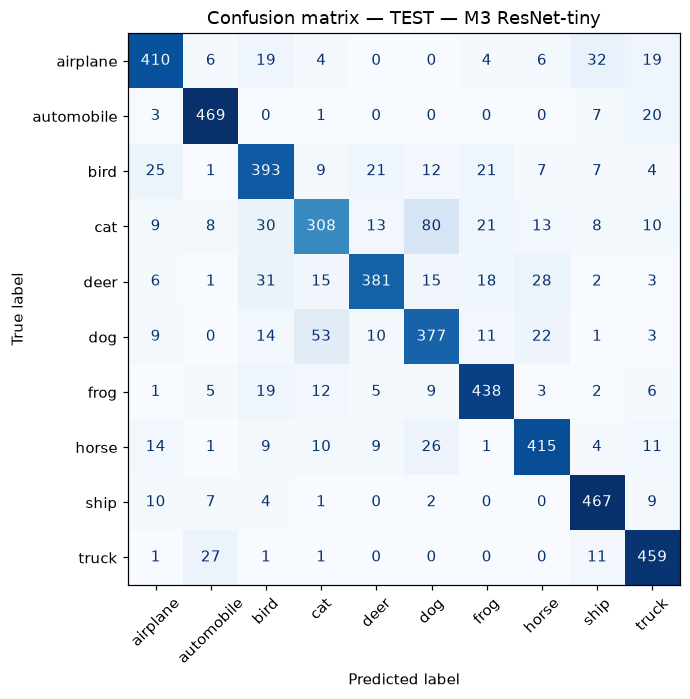

Đã lưu checkpoint, dự đoán và report trong: C:\Users\THINKPAD P1\Downloads\TH_TTNT\Bai_5_CNN_ban_nop\ket_qua


In [24]:
# CHỈ PHẦN NÀY mới sử dụng test_loader cho đánh giá mô hình.
best_name = summary_df.loc[0, "model"]
best_model = BEST_MODELS[best_name].to(DEVICE)
final_test = test_model(best_model, test_loader, criterion, DEVICE, CLASS_NAMES)

print("MÔ HÌNH CHỌN THEO VALIDATION:", best_name)
print(f"Validation loss = {summary_df.loc[0, 'val_loss']:.4f} | "
      f"Validation accuracy = {summary_df.loc[0, 'val_acc']:.2%}")
print(f"TEST loss = {final_test['loss']:.4f} | "
      f"TEST accuracy = {final_test['accuracy']:.2%} | "
      f"n_test = {final_test['n_samples']}")
print("\nCLASSIFICATION REPORT (chỉ mô hình cuối):")
print(final_test["classification_report"])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(final_test["confusion_matrix"], display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title(f"Confusion matrix — TEST — {best_name}")
plt.tight_layout()
plt.show()
pd.DataFrame({"true_label": final_test["y_true"],
              "pred_label": final_test["y_pred"]}).to_csv(RESULT_DIR / "du_doan_test_noi_bo.csv", index=False)
pd.DataFrame(final_test["confusion_matrix"], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RESULT_DIR / "confusion_matrix_test_noi_bo.csv")
(RESULT_DIR / "classification_report_test_noi_bo.txt").write_text(
    final_test["classification_report"], encoding="utf-8")
torch.save({"model_name": best_name, "state_dict": best_model.cpu().state_dict(),
            "mean": mu, "std": sigma, "class_names": CLASS_NAMES,
            "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
            "best_epoch": int(summary_df.loc[0, "best_epoch"])},
           RESULT_DIR / "mo_hinh_tot_nhat.pt")
best_model = best_model.to(DEVICE)
print("Đã lưu checkpoint, dự đoán và report trong:", RESULT_DIR)

### Bảng chỉ số test chi tiết

Tính các bảng từ cùng kết quả `final_test` vừa có, không đánh giá mô hình thêm lần nữa. Precision/recall/F1 có thang 0–1, support là số ảnh; accuracy tổng được ghi rõ đơn vị %. Test cân bằng 500 ảnh/lớp nên macro avg và weighted avg trùng nhau.

In [31]:
# Tính các bảng từ cùng nhãn/dự đoán của final_test đã có; không gọi test_model lần nữa.
report_dict = classification_report(final_test["y_true"], final_test["y_pred"],
    labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, zero_division=0, output_dict=True)
report_rows = [{"class": name, **report_dict[name]} for name in CLASS_NAMES + ["macro avg", "weighted avg"]]
test_report_table = pd.DataFrame(report_rows)
test_report_table["support"] = test_report_table["support"].astype(int)
print("PRECISION / RECALL / F1 / SUPPORT — TEST NỘI BỘ:")
display(test_report_table.style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1-score": "{:.4f}", "support": "{:d}"}))
n_correct = int((final_test["y_true"] == final_test["y_pred"]).sum())
test_global_table = pd.DataFrame([
    {"Chỉ số": "Số ảnh test nội bộ", "Giá trị": final_test["n_samples"], "Đơn vị": "ảnh"},
    {"Chỉ số": "Dự đoán đúng", "Giá trị": n_correct, "Đơn vị": "ảnh"},
    {"Chỉ số": "Dự đoán sai", "Giá trị": final_test["n_samples"] - n_correct, "Đơn vị": "ảnh"},
    {"Chỉ số": "Accuracy", "Giá trị": 100 * final_test["accuracy"], "Đơn vị": "%"},
    {"Chỉ số": "Cross-entropy loss", "Giá trị": final_test["loss"], "Đơn vị": "loss"},
    {"Chỉ số": "Macro precision", "Giá trị": report_dict["macro avg"]["precision"], "Đơn vị": "[0, 1]"},
    {"Chỉ số": "Macro recall", "Giá trị": report_dict["macro avg"]["recall"], "Đơn vị": "[0, 1]"},
    {"Chỉ số": "Macro F1", "Giá trị": report_dict["macro avg"]["f1-score"], "Đơn vị": "[0, 1]"},
])
shown_global = test_global_table.copy()
shown_global["Giá trị"] = [f"{value:.0f}" if unit == "ảnh" else f"{value:.2f}" if unit == "%" else f"{value:.4f}"
                          for value, unit in zip(shown_global["Giá trị"], shown_global["Đơn vị"])]
display(shown_global)
test_report_table.to_csv(RESULT_DIR / "classification_report_test_chi_tiet.csv", index=False)
test_global_table.to_csv(RESULT_DIR / "chi_so_test_tong_hop.csv", index=False)

PRECISION / RECALL / F1 / SUPPORT — TEST NỘI BỘ:


,class,precision,recall,f1-score,support
0,airplane,0.8402,0.8200,0.8300,500
1,automobile,0.8933,0.9380,0.9151,500
2,bird,0.7558,0.7860,0.7706,500
3,cat,0.7440,0.6160,0.6740,500
4,deer,0.8679,0.7620,0.8115,500
5,dog,0.7236,0.7540,0.7385,500
6,frog,0.8521,0.8760,0.8639,500
7,horse,0.8401,0.8300,0.8350,500
8,ship,0.8632,0.9340,0.8972,500
9,truck,0.8438,0.9180,0.8793,500


,Chỉ số,Giá trị,Đơn vị
0,Số ảnh test nội bộ,5000,ảnh
1,Dự đoán đúng,4117,ảnh
2,Dự đoán sai,883,ảnh
3,Accuracy,82.34,%
4,Cross-entropy loss,0.5104,loss
5,Macro precision,0.8224,"[0, 1]"
6,Macro recall,0.8234,"[0, 1]"
7,Macro F1,0.8215,"[0, 1]"


**Kết quả test cuối:** Mô hình **M3 ResNet-tiny**, đã được chọn chỉ bằng validation, đạt **accuracy 82.34%** và **cross-entropy loss 0.5104** trên **5,000 ảnh test nội bộ**. Số dự đoán đúng là **4117/5000**.

Precision, recall, F1 và support từng lớp cùng ma trận nhầm lẫn được hiển thị ở trên. Đây là kết quả trên phần giữ lại từ dữ liệu có nhãn Kaggle, không phải điểm trên test Kaggle hay test chính thức của CIFAR-10 gốc. Không chỉnh mô hình theo kết quả này.

## BT9. Quan sát feature maps

Áp dụng phần 11 của bài mẫu cho một **ảnh validation**. Lấy đầu ra của Conv2d đầu tiên,
vẽ tối đa 8 kênh. Màu của feature map thể hiện giá trị kích hoạt, không phải màu RGB
của ảnh. Đây là minh họa phản ứng của filter, không phải bằng chứng mô hình luôn đúng.

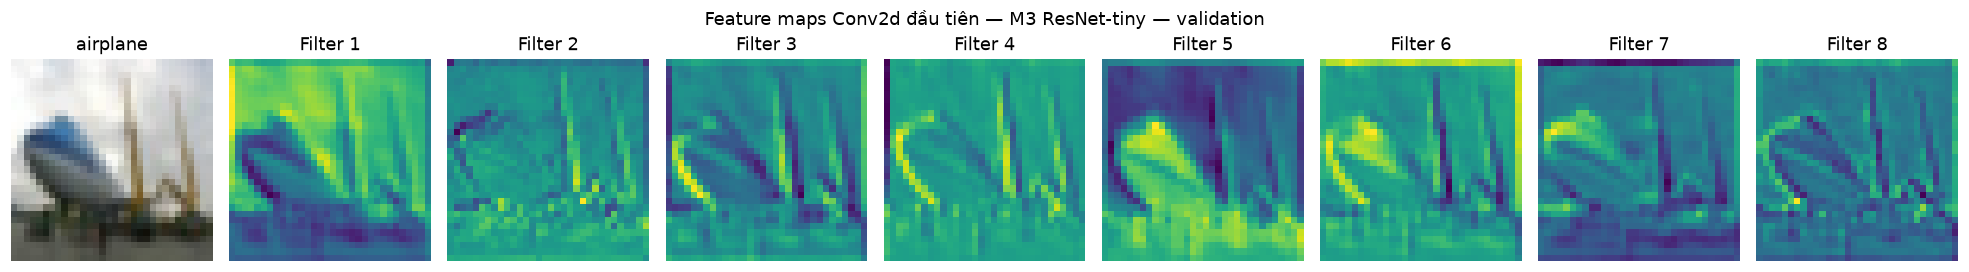

Đầu ra Conv2d đầu tiên: (16, 32, 32)


In [25]:
best_model.eval()
first_conv = next(m for m in best_model.modules() if isinstance(m, nn.Conv2d))
example_img, example_label = val_loader.dataset[0]
with torch.no_grad():
    maps = first_conv(example_img.unsqueeze(0).to(DEVICE)).cpu()[0]
num_show = min(8, maps.shape[0])
fig, axes = plt.subplots(1, num_show + 1, figsize=(2 * (num_show + 1), 2.5))
axes[0].imshow(X_val[0].permute(1, 2, 0))
axes[0].set_title(CLASS_NAMES[int(example_label)])
axes[0].axis("off")
for j in range(num_show):
    axes[j + 1].imshow(maps[j], cmap="viridis")
    axes[j + 1].set_title(f"Filter {j + 1}")
    axes[j + 1].axis("off")
plt.suptitle(f"Feature maps Conv2d đầu tiên — {best_name} — validation")
plt.tight_layout()
plt.show()
print("Đầu ra Conv2d đầu tiên:", tuple(maps.shape))

## BT10. Kết luận và giới hạn

Bài 5 lên CIFAR-10: xử lý ảnh RGB, giữ kiến trúc,
dùng lại các hàm huấn luyện/đánh giá, chạy tám cấu hình, so sánh bằng validation,
phân tích ảnh dự đoán sai, rồi đánh giá mô hình cuối trên test nội bộ.

Các mạng là phiên bản tiny đúng như tài liệu, không phải VGG-16/GoogLeNet/ResNet-18 chuẩn.
Một seed và 16 epoch chưa đủ kết luận kiến trúc nào luôn tốt hơn. Các phép biến đổi
chỉ giới hạn ở augmentation đã học; chưa tách riêng từng tác động của Dropout/weight decay.
Không sử dụng mô hình huấn luyện sẵn, transfer learning, scheduler hay kỹ thuật ngoài bài.

**Tái lập:** dùng đúng dữ liệu và danh sách chia trong `ket_qua/danh_sach_chia_du_lieu.csv`,
giữ seed/cấu hình, chạy các cell của phần lời giải theo thứ tự. Kết quả có thể chênh nhẹ
giữa thiết bị hoặc phiên bản PyTorch. Các nhận xét có số bên trên ứng với lần chạy đã lưu;
nếu đổi cấu hình, cần cập nhật nhận xét theo outputs mới.

**Kết luận từ số liệu:** Từ E0 đến E1, validation accuracy tăng 5,06 đpt; thêm Dropout và weight decay
(E1→E2) làm accuracy giảm nhẹ 0,10 đpt nhưng loss giảm. Augmentation (E2→E3) tăng accuracy 1,50 đpt
và giảm gap từ 8,06 xuống 1,74 đpt; BatchNorm (E3→E4) tăng tiếp 0,84 đpt.
Trong ba mạng tiny, ResNet-tiny có validation loss thấp nhất và được chọn theo quy tắc đã đặt trước.
Test cuối đạt 82,34%; các giá trị này phản ánh một seed, một phép chia và 16 epoch.

**Nguồn kiến thức:** notebook *Bài 5. Phân loại ảnh với CNN.ipynb*.
Nguồn dữ liệu: [CIFAR-10 Kaggle](https://www.kaggle.com/c/cifar-10).
